# Gaussian toy model

The following notebook contains a series of tests on the Lipschitz constrained model using a gaussian function as the target function. The structure is as follows: First, we generate a gaussian function with a given standard deviation $\sigma$ and compute its Lipschitz constant. Then, we evaluate the optimal fit of an L-Lipschitz function to the gaussian function for a range of L values. This sets us up for comparison so we can verify that the Lipschitz constrained model is able to learn the optimal fit for a given L.

When these prerequisites are done we can examine when the model breaks down.

In [5]:
import os
import sys
import random
import numpy as np
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt


In [6]:

# "Homemade" modules
%load_ext autoreload
%autoreload 2
from Toy_utils import sine_function_train_data, gaussian_function_data, BasicDataset, calculate_lipschitz_constant, gaussian_lipschitz_constant, FWHM_calculation, gaussian_function
from lipschitz_floor import lipschitz_floor, lipschitz_floor_scan
from models import LipschitzModel, UnconstrainedModel
from train_eval import train, predict
#from models import UnconstrainedModel, LipschitzModel
#from train_eval import train, evaluate, predict

os.makedirs("Plots/Toy", exist_ok=True)  # all figures of this notebook are saved here

PANEL_SIZE = (3.1, 2.8)  # inches, square-ish, close to the final size of a 0.48\textwidth subfigure (two side by side)

# One style for all report figures: the same text size everywhere, a closed black frame, no grid, no legend box
REPORT_STYLE = {
    "font.size": 12, "axes.labelsize": 12, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": True, "axes.spines.right": True, "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
    "axes.grid": False, "axes.axisbelow": True,
    "legend.frameon": False, "legend.handlelength": 1.6, "figure.dpi": 150, "savefig.bbox": "tight",
}


# The Gaussian function
The Gaussian function is defined as:
$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{x^2}{2\sigma^2}\right)
$$
We can set $\mu=0$ for simplicity as we are only interested in the shape and the gradients of the function. The Lipschitz constant of the Gaussian function is inversely proportional to the standard deviation $\sigma$ of the Gaussian. The sharper the Gaussian, the higher the Lipschitz constant.

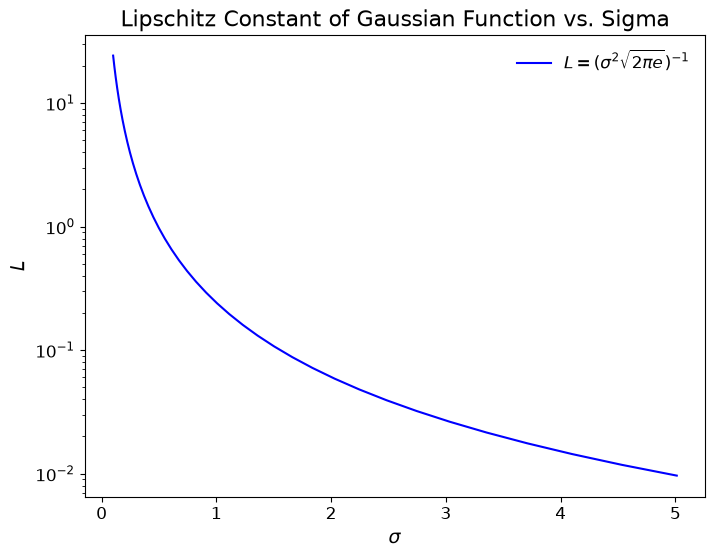

In [3]:
# The Lipschitz constant as a function of the standard deviation
sigma_values = np.logspace(-1, 0.7, 40)  # Example range of sigma values
#sigma_values = np.linspace(0.1, 2.0, 20)  # Example range of sigma values
L_gaussian = gaussian_lipschitz_constant(sigma_values)

plt.figure(figsize=(8, 6))
plt.plot(sigma_values, L_gaussian, label='$L=(\\sigma^2 \\sqrt{2\\pi e})^{-1}$', color='blue')

plt.yscale('log')
plt.xlabel('$\\sigma$', fontsize=14)
plt.ylabel('$L$', fontsize=14)
#plt.grid(True)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, frameon=False)
plt.savefig('Plots/Toy/Gaussian_lipschitz_constant.pdf')            # vector version, for LaTeX
plt.title('Lipschitz Constant of Gaussian Function vs. Sigma', fontsize=16)
plt.show()


In other words, the sharper the gaussian, the higher the Lipschitz constant.

# Floor function
The first part is to establish the theoretical baseline for the best possible fit. Through a quadratic programming approach we can compute the best possible L-Lipschitz fit to a gaussian function. Doing this for a range of L values lets us examine how the errors propagate as we move away from the true Lipschitz constant, as well as how the errors change with sharper gaussians

## Fitting the floor function

In [4]:

from lipschitz_floor import lipschitz_floor_scan
# Generating a gaussian to train on
N = 2000
MU = 0
SIGMA = 0.1
NOISE_MAGNITUDE = 0.1

x_gaussian_train, y_gaussian_train, x_gaussian_linspace, y_gaussian_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)

L_true_gaussian = gaussian_lipschitz_constant(SIGMA)
print(f'True Lipschitz constant of the Gaussian function: {L_true_gaussian:.4f}')


True Lipschitz constant of the Gaussian function: 24.1971


In [5]:
# Optimal Floor fits for selected L-Lipschitz constants

# Making the narrow gaussian
N = 2000
MU = 0
SIGMA = 0.1
NOISE_MAGNITUDE = 0.1
_, _, x_linspace, y_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)
L_true = gaussian_lipschitz_constant(SIGMA)
x_np = x_linspace.numpy().ravel()  # flat arrays: with shape (N, 1), differences like floor - y would broadcast to N x N
y_np = y_linspace.numpy().ravel()

# Selected L values for the floor fits
L_show = [L for L in [1, 3, 10, 20] if L < L_true]  # for L >= L_true the floor is the truth itself
floors = {L: lipschitz_floor(x_np, y_np, L)[0] for L in L_show}

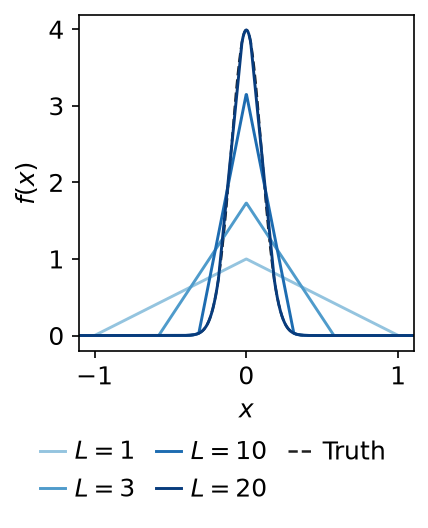

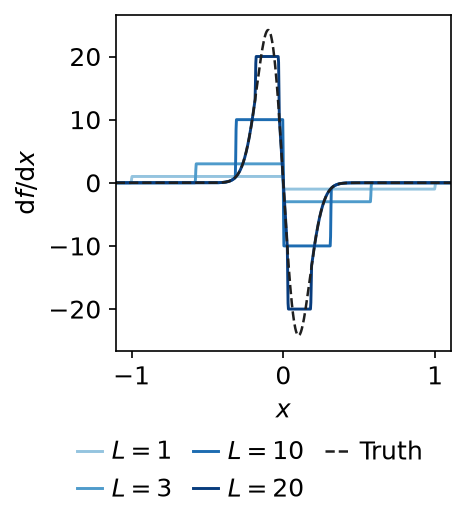

In [6]:
# Zoom to where the floors differ visibly from the truth (but stay inside the fitted range)
peak_true = y_np.max()
differs = np.any([np.abs(g - y_np) > 0.01 * peak_true for g in floors.values()], axis=0)
half_width = 1.15 * np.abs(x_np[differs] - MU).max() if differs.any() else 4 * SIGMA
x_lo, x_hi = max(x_np.min(), MU - half_width), min(x_np.max(), MU + half_width)


# --- Figures for the report
C_TRUE, C_FLOOR, C_NET, C_MUTED = "#1f1f1f", "#2a78d6", "#eb6834", "#6b6a66"
shades = plt.cm.Blues(np.linspace(0.4, 0.95, len(L_show)))  # one hue, light -> dark = small -> large L

PANEL_SIZE = (3.1, 2.8)  # inches, square-ish, close to the final size of a 0.48\textwidth subfigure (two side by side)

# One style for all report figures: the same text size everywhere, a closed black frame, no grid, no legend box
REPORT_STYLE = {
    "font.size": 12, "axes.labelsize": 12, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": True, "axes.spines.right": True, "axes.edgecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
    "axes.grid": False, "axes.axisbelow": True,
    "legend.frameon": False, "legend.handlelength": 1.6, "figure.dpi": 150, "savefig.bbox": "tight",
}

# Figures that sit side by side in the report (theory next to experiment) must be exactly the same size, with the axes
# in the same place. So they get a fixed size and fixed margins, and are saved WITHOUT the tight cropping
# (tight cropping makes a figure with a wider legend a different size, and LaTeX then shrinks its plot).
PAIR_SIZE = (3.1, 3.5)                                         # inches, room for the plot and a two-row legend below
PAIR_MARGINS = dict(left=0.24, right=0.96, top=0.97, bottom=0.33)   # left: room for wide tick labels like -20 and the y-label
PAIR_LEGEND = dict(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=3,
                   handlelength=1.0, columnspacing=0.8, handletextpad=0.4, frameon=False)


with plt.rc_context(REPORT_STYLE), plt.rc_context({"savefig.bbox": "standard"}):
    # (a) What the floor looks like for different L
    fig, ax = plt.subplots(figsize=PAIR_SIZE)
    fig.subplots_adjust(**PAIR_MARGINS)
    truth_line, = ax.plot(x_np, y_np, color=C_TRUE, lw=1.2, ls="--", label="Truth")
    floor_lines = []
    for L, c in zip(L_show, shades):
        line, = ax.plot(x_np, floors[L], color=c, lw=1.4, label=rf"$L = {L:g}$")
        floor_lines.append(line)
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
    # Legend below the panel: the L values first, then the truth
    ax.legend(handles=floor_lines + [truth_line], **PAIR_LEGEND)
    fig.savefig("Plots/Toy/gaussian_cost_floor_fits.pdf")
    plt.show()

# Slopes of the floor fits (theory), in the same format as the slopes of the networks (experiment).
# Uses REPORT_STYLE, PAIR_SIZE, PAIR_MARGINS, PAIR_LEGEND, C_TRUE and shades from the floor-fit plot cell above.

# Slope of the Gaussian and of every floor, computed on the grid
slope_true = np.gradient(y_np, x_np)
floor_slopes = {}
for L in L_show:
    floor_slopes[L] = np.gradient(floors[L], x_np)

with plt.rc_context(REPORT_STYLE), plt.rc_context({"savefig.bbox": "standard"}):
    # The Gaussian needs slopes up to +-L_true. The floor with L < L_true cannot follow, so it rises at exactly +L
    # from where it leaves the Gaussian up to the peak, and falls at exactly -L on the other side: a tent.
    fig, ax = plt.subplots(figsize=PAIR_SIZE)
    fig.subplots_adjust(**PAIR_MARGINS)
    slope_lines = []
    for L, c in zip(L_show, shades):
        line, = ax.plot(x_np, floor_slopes[L], color=c, lw=1.4, label=rf"$L = {L:g}$")
        slope_lines.append(line)
    # The Gaussian is drawn last, so it stays visible on top of the floor that follows it in the tails
    truth_slope_line, = ax.plot(x_np, slope_true, color=C_TRUE, lw=1.2, ls="--", label="Truth")
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$\mathrm{d}f/\mathrm{d}x$")
    ax.legend(handles=slope_lines + [truth_slope_line], **PAIR_LEGEND)
    fig.savefig("Plots/Toy/gaussian_floor_slopes.pdf")
    plt.show()


The floor function is the best possible L-Lipschitz approximation to the Gaussian function. The floor function optimizes the height and uses linear segments within the Lipschitz budget to connect the points. This manifests as a tent-like structure that gradually approaches the height of the Gaussian function as L increases to $L_\mathrm{true}$.

## MSE of the floor function
Calculating the evolution of the MSE of the floor function.

In [7]:

# Scan of L values
L_true = gaussian_lipschitz_constant(SIGMA)
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true:.4f}")
L_scan = np.logspace(np.log10(0.01 * L_true), np.log10(2 * L_true), 40)

# Compute MSE
floor_dict, MSE_dict = {}, {}
for L in L_scan:
    print(f"Computing Lipschitz floor for L={L:.4f}")
    floor_dict[str(L)], MSE_dict[str(L)] = lipschitz_floor(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L)

#MSE_floors = lipschitz_floor_scan(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L_scan)


Lipschitz constant of the Gaussian function with sigma=0.1: 24.1971
Computing Lipschitz floor for L=0.2420
Computing Lipschitz floor for L=0.2772
Computing Lipschitz floor for L=0.3175
Computing Lipschitz floor for L=0.3637
Computing Lipschitz floor for L=0.4166
Computing Lipschitz floor for L=0.4773
Computing Lipschitz floor for L=0.5467
Computing Lipschitz floor for L=0.6263
Computing Lipschitz floor for L=0.7174
Computing Lipschitz floor for L=0.8218
Computing Lipschitz floor for L=0.9414
Computing Lipschitz floor for L=1.0784
Computing Lipschitz floor for L=1.2353
Computing Lipschitz floor for L=1.4151
Computing Lipschitz floor for L=1.6210
Computing Lipschitz floor for L=1.8568
Computing Lipschitz floor for L=2.1270
Computing Lipschitz floor for L=2.4366
Computing Lipschitz floor for L=2.7911
Computing Lipschitz floor for L=3.1973
Computing Lipschitz floor for L=3.6625
Computing Lipschitz floor for L=4.1955
Computing Lipschitz floor for L=4.8060
Computing Lipschitz floor for L=5.5

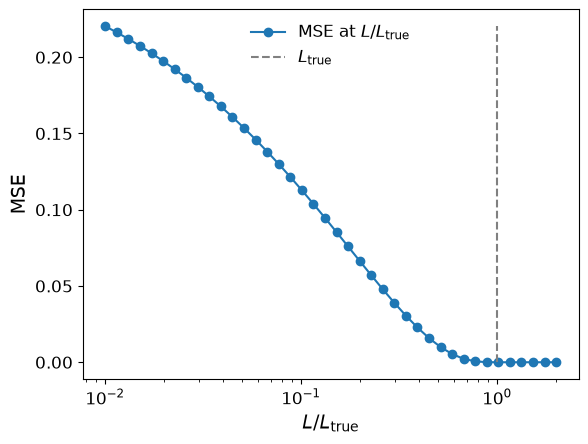

In [9]:
# Plotting the MSE of the best Lipschitz fit as a function of L
MSE_floors = list(MSE_dict.values())
plt.plot(L_scan/L_true, MSE_floors, '-o', label='${\\mathrm{MSE}}$ at $L/L_{\\mathrm{true}}$')
plt.vlines(1.0, ymin=min(MSE_floors), ymax=max(MSE_floors), colors='grey', linestyles='dashed', label='$L_{\\mathrm{true}}$')
plt.xscale('log')
#plt.yscale('log')
plt.xlabel(r'$L / L_{\text{true}}$', fontsize=14)
plt.ylabel('MSE', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
#plt.grid()
#plt.title('MSE of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend(fontsize=12, frameon=False, loc="upper center")
plt.savefig('Plots/Toy/Gaussian_MSE_floors.pdf')
plt.show()

## FWMH of the floor function

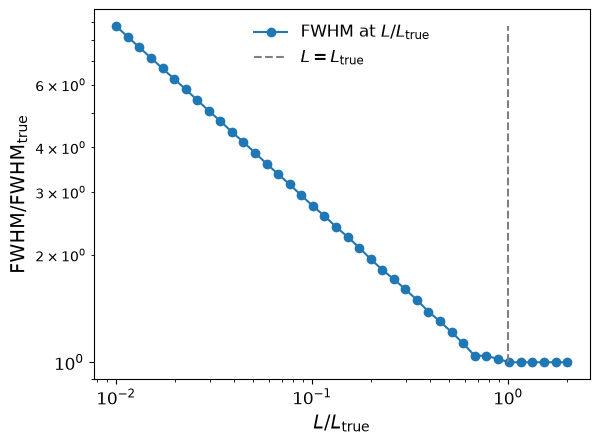

In [10]:
# Plotting the FWHM of the best Lipschitz fit as a function of L
x_fwhm = x_gaussian_linspace.numpy().ravel()
FWHM_values = np.array([FWHM_calculation(x_fwhm, floor_dict[str(L)]) for L in L_scan])
FWHM_true = FWHM_calculation(x_fwhm, y_gaussian_linspace.numpy().ravel())
plt.plot(L_scan/L_true, FWHM_values/FWHM_true, '-o', label='${\\mathrm{FWHM}}$ at $L/L_{\\mathrm{true}}$')
plt.vlines(1.0, ymin=min(FWHM_values/FWHM_true), ymax=max(FWHM_values/FWHM_true), colors='grey', linestyles='dashed', label='$L=L_{\\mathrm{true}}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$L / L_{\text{true}}$', fontsize=14)
plt.ylabel(r'$\text{FWHM}/\text{FWHM}_{\text{true}}$', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
#plt.grid()
#plt.title('FWHM of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend(loc='upper center',fontsize=12, frameon=False)
plt.savefig('Plots/Toy/Gaussian_FWHM_floors.pdf')
plt.show()

## Investigatign the MSE and FWHM kink close to the $L_\mathrm{true}$ point
Observing the kink in the plots for the MSE and FWHM. By scanning a smaller range of L values we can investigate the kink in more detail. Hypothesis: the kink is due to the fact that the height of the function is high enough and the function can start optimalizing the width, making piecewise linear segments to recreate the curve of the Gaussian.

In [ ]:

# Scan of L values
L_true = gaussian_lipschitz_constant(SIGMA)
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true:.4f}")
L_scan = np.logspace(np.log10(0.3 * L_true), np.log10(1.01*L_true), 40)

# Compute MSE
floor_dict, MSE_dict = {}, {}
for L in L_scan:
    print(f"Computing Lipschitz floor for L={L:.4f}")
    floor_dict[str(L)], MSE_dict[str(L)] = lipschitz_floor(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L)

#MSE_floors = lipschitz_floor_scan(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L_scan)

Lipschitz constant of the Gaussian function with sigma=0.1: 24.1971
Computing Lipschitz floor for L=9.6788
Computing Lipschitz floor for L=9.9115
Computing Lipschitz floor for L=10.1497
Computing Lipschitz floor for L=10.3936
Computing Lipschitz floor for L=10.6434
Computing Lipschitz floor for L=10.8992
Computing Lipschitz floor for L=11.1612
Computing Lipschitz floor for L=11.4294
Computing Lipschitz floor for L=11.7041
Computing Lipschitz floor for L=11.9854
Computing Lipschitz floor for L=12.2735
Computing Lipschitz floor for L=12.5684
Computing Lipschitz floor for L=12.8705
Computing Lipschitz floor for L=13.1798
Computing Lipschitz floor for L=13.4966
Computing Lipschitz floor for L=13.8210
Computing Lipschitz floor for L=14.1532
Computing Lipschitz floor for L=14.4933
Computing Lipschitz floor for L=14.8416
Computing Lipschitz floor for L=15.1983
Computing Lipschitz floor for L=15.5636
Computing Lipschitz floor for L=15.9377
Computing Lipschitz floor for L=16.3207
Computing Lips

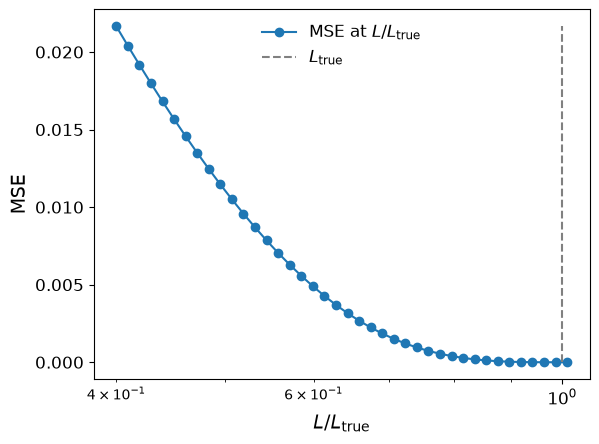

In [12]:
# Plotting the MSE of the best Lipschitz fit as a function of L
MSE_floors = list(MSE_dict.values())
plt.plot(L_scan/L_true, MSE_floors, '-o', label='${\\mathrm{MSE}}$ at $L/L_{\\mathrm{true}}$')
plt.vlines(1.0, ymin=min(MSE_floors), ymax=max(MSE_floors), colors='grey', linestyles='dashed', label='$L_{\\mathrm{true}}$')
plt.xscale('log')
#plt.yscale('log')
plt.xlabel(r'$L / L_{\text{true}}$', fontsize=14)
plt.ylabel('MSE', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
#plt.grid()
#plt.title('MSE of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend(fontsize=12, frameon=False, loc="upper center")
plt.savefig('Plots/Toy/Gaussian_MSE_floors_zoom.pdf')
plt.show()

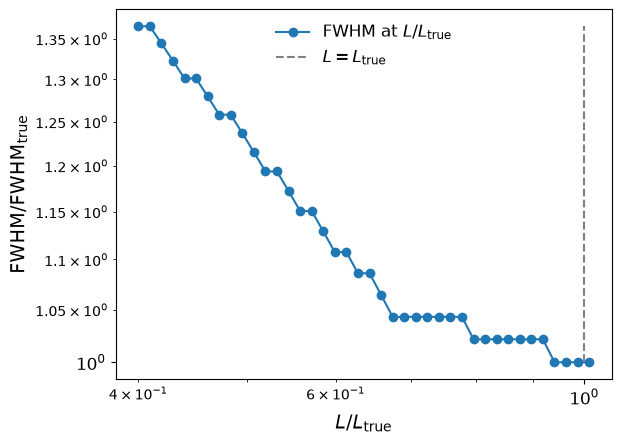

In [13]:
# Plotting the FWHM of the best Lipschitz fit as a function of L
x_fwhm = x_gaussian_linspace.numpy().ravel()
FWHM_values = np.array([FWHM_calculation(x_fwhm, floor_dict[str(L)]) for L in L_scan])
FWHM_true = FWHM_calculation(x_fwhm, y_gaussian_linspace.numpy().ravel())
plt.plot(L_scan/L_true, FWHM_values/FWHM_true, '-o', label='${\\mathrm{FWHM}}$ at $L/L_{\\mathrm{true}}$')
plt.vlines(1.0, ymin=min(FWHM_values/FWHM_true), ymax=max(FWHM_values/FWHM_true), colors='grey', linestyles='dashed', label='$L=L_{\\mathrm{true}}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$L / L_{\text{true}}$', fontsize=14)
plt.ylabel(r'$\text{FWHM}/\text{FWHM}_{\text{true}}$', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
#plt.grid()
#plt.title('FWHM of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend(loc='upper center',fontsize=12, frameon=False)
plt.savefig('Plots/Toy/Gaussian_FWHM_floors_zoom.pdf')
plt.show()

We observe that the MSE is decreasing similar to a quadratic function, as expected from the definition of the optimizing criterion. The FWHM is also decreasing, but almost stepwise. I interpret this as the floor function starting to optimize the width by adding more linear segments to the floor function. 

## Integrated Floor errors compared

A sanity check to compare the different combinations of the Lischitz constants and the standard deviations of the Gaussian functions. Essentially just reconfirming that different combinations are just rescalings of one another.

In [14]:
# Calculating different error measures for the best Lipschitz fit as a function of L
def integrated_squared_error(f, g, x):
    """Compute the integrated squared error between two functions f and g over the domain x."""
    return np.trapezoid((f - g) ** 2, x)

def integrated_abs_error(f, g, x):
    """Compute the integrated absolute error between two functions f and g over the domain x."""
    return np.trapezoid(np.abs(f - g), x)

# Iterating through different combinations of sigma and L/L_true
sigma_values = np.logspace(-1, 0.5, 10)
r_values = np.logspace(-2, np.log10(2), 30)  # L / L_true, the same grid for every sigma
POINTS_PER_SIGMA = 40                         # the same resolution for every sigma, so the discretisation error is the same

# Initializing matrices
ISE_matrix = np.zeros((len(sigma_values), len(r_values)))
IAE_matrix = np.zeros_like(ISE_matrix)

for i, sigma in enumerate(sigma_values):
    L_true_sigma = gaussian_lipschitz_constant(sigma)   # own name, so the global L_true is not overwritten
    for j, r in enumerate(r_values):
        L = r * L_true_sigma

        # Need to scale each range with the sigma so we contain similar features for all combinations of sigma and L
        tent_half_width = np.sqrt(1 / L) # Unit area gaussian => w_L = sqrt(area / L) = sqrt(1 / L)
        half_width = max(6 * sigma, 1.5 * tent_half_width)
        n_points = int(2 * half_width / sigma * POINTS_PER_SIGMA) + 1

        x = np.linspace(-half_width, half_width, n_points)
        y = gaussian_function(x, MU, sigma)
        floor, _ = lipschitz_floor(x, y, L)   # Calculating the floor function for the current combination

        ISE_matrix[i, j] = integrated_squared_error(y, floor, x)
        IAE_matrix[i, j] = integrated_abs_error(y, floor, x)
    print(f"sigma = {sigma:.2f} done")


sigma = 0.10 done
sigma = 0.15 done
sigma = 0.22 done
sigma = 0.32 done
sigma = 0.46 done
sigma = 0.68 done
sigma = 1.00 done
sigma = 1.47 done
sigma = 2.15 done
sigma = 3.16 done


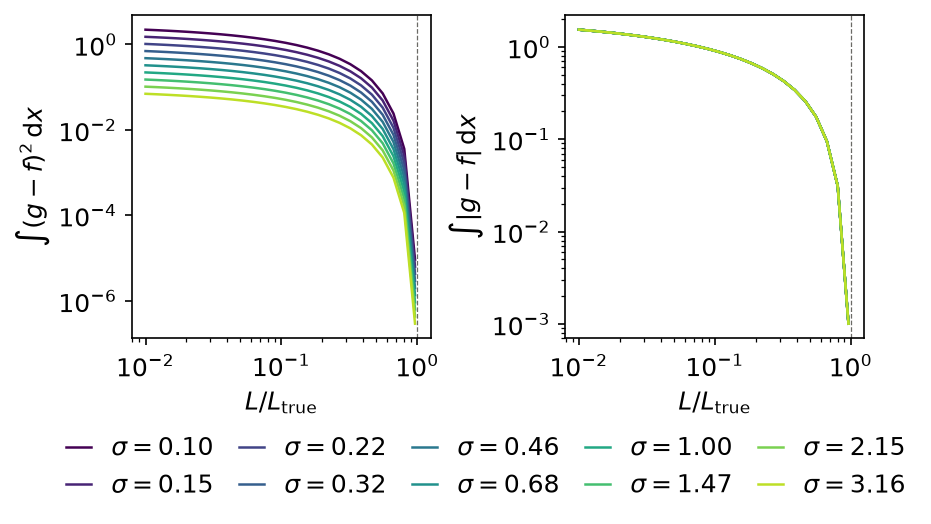

In [17]:
# The squared and the absolute error side by side, with one shared legend underneath
# Uses REPORT_STYLE and C_MUTED from the floor-fit plot cell above.
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sigma_values)))   # one colour per sigma

# Zeros (L >= L_true, where the floor equals the truth) cannot be drawn on a log axis, so they are replaced by NaN
ISE_for_plot = np.where(ISE_matrix > 0, ISE_matrix, np.nan)
IAE_for_plot = np.where(IAE_matrix > 0, IAE_matrix, np.nan)

with plt.rc_context(REPORT_STYLE):
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8), gridspec_kw=dict(wspace=0.45))
    ax_squared = axs[0]
    ax_absolute = axs[1]

    # (a) Integrated squared error: spreads out with sigma (scales as 1/sigma)
    for i in range(len(sigma_values)):
        ax_squared.plot(r_values, ISE_for_plot[i], color=colors[i], lw=1.2, label=rf"$\sigma = {sigma_values[i]:.2f}$")
    ax_squared.axvline(1, color=C_MUTED, lw=0.6, ls="--")
    ax_squared.set_xscale("log")
    ax_squared.set_yscale("log")
    ax_squared.yaxis.set_major_locator(plt.LogLocator(numticks=4))   # fewer tick labels, the axis spans many decades
    ax_squared.set_xlabel(r"$L / L_\mathrm{true}$")
    ax_squared.set_ylabel(r"$\int (g - f)^2\,\mathrm{d}x$")

    # (b) Integrated absolute error: the same for every sigma, the curves lie on top of each other
    for i in range(len(sigma_values)):
        ax_absolute.plot(r_values, IAE_for_plot[i], color=colors[i], lw=1.2)
    ax_absolute.axvline(1, color=C_MUTED, lw=0.6, ls="--")
    ax_absolute.set_xscale("log")
    ax_absolute.set_yscale("log")
    ax_absolute.set_xlabel(r"$L / L_\mathrm{true}$")
    ax_absolute.set_ylabel(r"$\int |g - f|\,\mathrm{d}x$")

    # One shared legend underneath both panels, in five columns so it is only two rows high
    legend_lines, legend_labels = ax_squared.get_legend_handles_labels()
    fig.legend(legend_lines, legend_labels, loc="upper center", bbox_to_anchor=(0.5, -0.07),
               ncol=5, handlelength=1.0, columnspacing=1.0)

    fig.savefig("Plots/Toy/gaussian_floor_error_squared_and_absolute.pdf")
    plt.show()



# Trained networks against the floor
The same Gaussian ($\sigma = 0.1$) and the same Lipschitz constants as the floor fits above, now learned by Lipschitz networks (width 64, depth 5, GroupSort with 8 groups, full-batch Adam, 3 seeds each), together with an unconstrained network of the same size as a reference. The networks are trained on the clean target, so they can be compared directly with the floor.

The figures use the same format as the floor fits, but in orange (implementation) instead of blue (theory). If the networks perform as expected, they reproduce the floor and use their full slope budget: the slope sits at exactly $\pm L$ on the sides of the tent. Runtime about 10 minutes.

In [63]:
# Train Lipschitz networks on the same Gaussian (sigma = 0.1) for the same L values as the floor fits above
from Toy_utils import train_full_batch

# Hyperparameters for the networks
SEEDS_NET = [0, 1, 2]
HIDDEN_DIM_NET, N_GROUPS_NET, DEPTH_NET = 64, 8, 5



x_tensor = torch.tensor(x_np, dtype=torch.float32).unsqueeze(-1)
y_tensor = torch.tensor(y_np, dtype=torch.float32).unsqueeze(-1)  # clean target, so we can compare with the floor

net_fits, net_slopes = {}, {}  # net_fits[L], net_slopes[L]: arrays of shape (number of seeds, number of points)
for L in L_show:
    fits, slopes = [], []
    for seed in SEEDS_NET:
        torch.manual_seed(seed)
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM_NET, output_dim=1, n_groups=N_GROUPS_NET,
                               depth=DEPTH_NET, lipschitz_bound=L)
        train_full_batch(model, x_tensor, y_tensor)

        # Output and slope df/dx of the trained network at every grid point (slope via autograd)
        x_req = x_tensor.clone().requires_grad_(True)
        out = model(x_req)
        slope, = torch.autograd.grad(out.sum(), x_req)
        fits.append(out.detach().numpy().ravel())
        slopes.append(slope.numpy().ravel())
    net_fits[L], net_slopes[L] = np.array(fits), np.array(slopes)
    print(f"L = {L}: trained {len(SEEDS_NET)} seeds")

# Unconstrained reference: same size and training, no Lipschitz bound
unc_fits, unc_slopes = [], []
for seed in SEEDS_NET:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM_NET, output_dim=1, depth=DEPTH_NET)
    train_full_batch(model, x_tensor, y_tensor)
    x_req = x_tensor.clone().requires_grad_(True)
    out = model(x_req)
    slope, = torch.autograd.grad(out.sum(), x_req)
    unc_fits.append(out.detach().numpy().ravel())
    unc_slopes.append(slope.numpy().ravel())
unc_fits, unc_slopes = np.array(unc_fits), np.array(unc_slopes)
print(f"Unconstrained: trained {len(SEEDS_NET)} seeds")

L = 1: trained 3 seeds
L = 3: trained 3 seeds
L = 10: trained 3 seeds
L = 20: trained 3 seeds
Unconstrained: trained 3 seeds


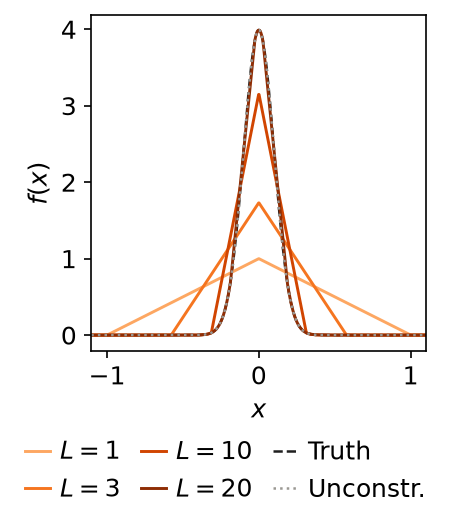

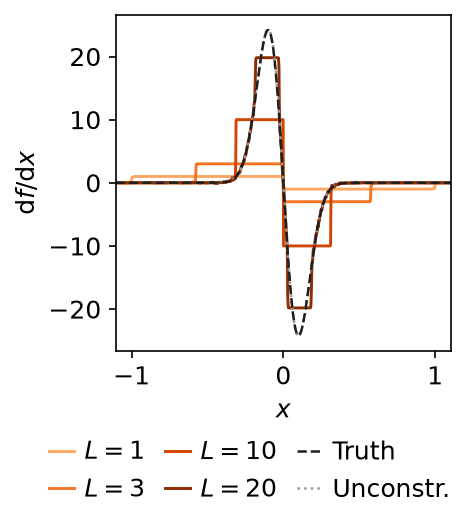

    L      L_hat / L      peak: net | floor      FWHM: net | floor           ISE: net | floor
    1    1.000 ± 0.000     0.999 |  0.999     0.998 |  0.998      1.6472 |    1.6472
    3    1.000 ± 0.000     1.728 |  1.728     0.578 |  0.578      0.9903 |    0.9903
   10    1.000 ± 0.000     3.147 |  3.147     0.313 |  0.313      0.1995 |    0.1995
   20    0.991 ± 0.003     3.988 |  3.989     0.238 |  0.238      0.0026 |    0.0022

Unconstrained: largest slope 24.1 ± 0.1 (L_true = 24.2), peak 3.989 (true 3.989), FWHM 0.233 (true 0.233), ISE 7.05e-07


In [77]:
# Network fits in the same format as the floor fits, in orange (implementation) instead of blue (theory).
# The floor fits are in their own figure, placed next to this one in the report, so they are not repeated here.
# Uses REPORT_STYLE, PAIR_SIZE, PAIR_MARGINS, PAIR_LEGEND and the colours from the floor-fit plot cell above.
net_shades = plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_show)))  # one hue, light -> dark = small -> large L
C_REF = "#9a9893"  # grey for the unconstrained reference, separate from theory (blue) and Lipschitz networks (orange)

with plt.rc_context(REPORT_STYLE), plt.rc_context({"savefig.bbox": "standard"}):
    # (a) Network fits: mean over seeds, band = spread between seeds
    fig, ax = plt.subplots(figsize=PAIR_SIZE)
    fig.subplots_adjust(**PAIR_MARGINS)
    truth_line, = ax.plot(x_np, y_np, color=C_TRUE, lw=1.2, ls="--", label="Truth")
    network_lines = []
    for L, c in zip(L_show, net_shades):
        ax.fill_between(x_np, net_fits[L].min(0), net_fits[L].max(0), color=c, alpha=0.3, lw=0)
        line, = ax.plot(x_np, net_fits[L].mean(0), color=c, lw=1.4, label=rf"$L = {L:g}$")
        network_lines.append(line)
    unconstrained_line, = ax.plot(x_np, unc_fits.mean(0), color=C_REF, lw=1.2, ls=":", label="Unconstr.")
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
    # Legend below the panel, in the same layout as the floor fits. The measured slopes L_hat are in the table below.
    ax.legend(handles=network_lines + [truth_line, unconstrained_line], **PAIR_LEGEND)
    fig.savefig("Plots/Toy/gaussian_network_fits.pdf")
    plt.show()

    # (b) Slopes of the network fits against the slope of the Gaussian itself.
    # The Gaussian needs slopes up to +-L_true. A network with L < L_true cannot follow, so it rises at its full
    # slope +L from where it leaves the Gaussian up to the peak, and falls at -L on the other side: a tent.
    # The plateaus at exactly +-L show that the networks use their whole slope budget.
    # The unconstrained network has no bound, so it follows the slope of the Gaussian.
    slope_true = np.gradient(y_np, x_np)   # slope of the Gaussian, computed on the grid
    fig, ax = plt.subplots(figsize=PAIR_SIZE)
    fig.subplots_adjust(**PAIR_MARGINS)
    slope_lines = []
    for L, c in zip(L_show, net_shades):
        line, = ax.plot(x_np, net_slopes[L].mean(0), color=c, lw=1.4, label=rf"$L = {L:g}$")
        slope_lines.append(line)
    unconstrained_slope_line, = ax.plot(x_np, unc_slopes.mean(0), color=C_REF, lw=1.2, ls=":", label="Unconstr.")
    # The Gaussian is drawn last, so it stays visible on top of the unconstrained network that follows it
    truth_slope_line, = ax.plot(x_np, slope_true, color=C_TRUE, lw=1.2, ls="--", label="Truth")
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$\mathrm{d}f/\mathrm{d}x$")
    ax.legend(handles=slope_lines + [truth_slope_line, unconstrained_slope_line], **PAIR_LEGEND)
    fig.savefig("Plots/Toy/gaussian_network_slopes.pdf")
    plt.show()

# --- Table: network (mean ± std over seeds) against the floor
print(f"{'L':>5} {'L_hat / L':>14} {'peak: net | floor':>22} {'FWHM: net | floor':>22} {'ISE: net | floor':>26}")
for L in L_show:
    L_hat = np.abs(net_slopes[L]).max(axis=1) / L
    peaks = net_fits[L].max(axis=1)
    widths = np.array([FWHM_calculation(x_np, f) for f in net_fits[L]])
    ise = np.array([np.trapezoid((f - y_np) ** 2, x_np) for f in net_fits[L]])
    print(f"{L:5g} {L_hat.mean():8.3f} ± {L_hat.std():.3f}"
          f"   {peaks.mean():7.3f} | {floors[L].max():6.3f}"
          f"   {widths.mean():7.3f} | {FWHM_calculation(x_np, floors[L]):6.3f}"
          f"   {ise.mean():9.4f} | {np.trapezoid((floors[L] - y_np) ** 2, x_np):9.4f}")

# Unconstrained reference: no bound, so its largest slope is compared with L_true of the target
L_hat_unc = np.abs(unc_slopes).max(axis=1)
widths_unc = np.array([FWHM_calculation(x_np, f) for f in unc_fits])
ise_unc = np.array([np.trapezoid((f - y_np) ** 2, x_np) for f in unc_fits])
print(f"\nUnconstrained: largest slope {L_hat_unc.mean():.1f} ± {L_hat_unc.std():.1f} (L_true = {L_true:.1f}), "
      f"peak {unc_fits.max(axis=1).mean():.3f} (true {y_np.max():.3f}), "
      f"FWHM {widths_unc.mean():.3f} (true {FWHM_calculation(x_np, y_np):.3f}), ISE {ise_unc.mean():.2e}")


The trained networks are able to reproduce the floor functions, showing that the current architecture finds optimal solutions for the given Lipcshitz constraints. Further, the closer one comes to the true Lipschitz constant, the better the slopes becomes. The Heaviside function like behaviour of the slopes could be due to the cap on gradients in the networks. The networks make piecewise linear segments to approximate the Gaussian function. The Lipschitz networks' approximation functions rise earlier than the gaussian, which preserves the area under curve for the approximated function.

# Added noise response
In this section, we will explore the response of the Lipschitz constrained model to added noise. Particularily we will examine how the model performs when the target function, a Gaussian, is corrupted with sine waves of varying frequencies and amplitudes. Hopefully this corroborates the Spectral Norm regularization paper and shows that Lipschitz networks are even more robust to this tyoe of noise than unconstrained networks.

In [7]:
# Sine Wave Noise generation
N = 2000
X_MIN, X_MAX = -5 , 5
SIGMA = 2.0 # Wide distribution
AMPLITUDES = [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5] # Amplitudes of the sine waves
MODES = [10, 20, 45, 60, 75, 95, 110, 120] # Must choose whole number modes to fit in the FFR without "leaking" into nearby frequencies
FREQUENCIES = [2*np.pi*n/(X_MAX-X_MIN) for n in MODES] # Rescaling to the grid to calculate the correct frequencies of the whole periods that fit in the FFR

print(f"Lipschitz constant of the Gaussian signal: {gaussian_lipschitz_constant(SIGMA):.4f}")

def sine_noise(amplitudes, frequencies, x):
    """Generate a sine wave noise signal."""
    np.random.seed(42)  # For reproducibility
    noise = np.zeros_like(x)
    for f, a in zip(frequencies, amplitudes):
        bias = 2*np.pi * np.random.uniform(-1, 1) # Shifting with random bias
        noise += a * np.sin(f * x + bias)
    return noise 

def fourier_spectrum(x, f):
    """
    Calculates the amplitude spectrum of f, sampled on the evenly spaced grid x.
    Returns the angular frequencies omega and the amplitude at each frequency.
    The amplitudes are scaled so that a term A * sin(omega * x) shows up as a peak of height A.
    """
    n = len(f)
    dx = x[1] - x[0]                          # grid spacing

    fourier = np.fft.rfft(f)                  # Fourier transform (only positive frequencies, since f is real)
    amplitude = 2 * np.abs(fourier) / n       # scale so a sine of amplitude A gives a peak of height A
    amplitude[0] = amplitude[0] / 2           # the constant term (omega = 0) should not be doubled

    frequency = np.fft.rfftfreq(n, d=dx)      # frequencies in cycles per unit of x
    omega = 2 * np.pi * frequency             # convert to angular frequency, to match sin(omega * x)
    return omega, amplitude

# Generating the Gaussian
x_gaussian_linspace = np.linspace(X_MIN, X_MAX, N, endpoint = False)
gaussian = np.exp(-0.5 * (x_gaussian_linspace / SIGMA) ** 2) / (SIGMA * np.sqrt(2 * np.pi))
noise = sine_noise(AMPLITUDES, FREQUENCIES, x_gaussian_linspace)
noisy_gaussian = gaussian + noise

# Lipschitz constant of the noise (THINK ABOUT THIS)

#print(f"Lipschitz constant of the sine noise: {calculate_lipschitz_constant(noise, x_gaussian_linspace):.4f}")

# Calculating the fourier spectra
omega_gaussian, amplitude_gaussian = fourier_spectrum(x_gaussian_linspace, gaussian)
omega_noise, amplitude_noise = fourier_spectrum(x_gaussian_linspace, noise)
omega_combined, amplitude_combined = fourier_spectrum(x_gaussian_linspace, noisy_gaussian)


Lipschitz constant of the Gaussian signal: 0.0605


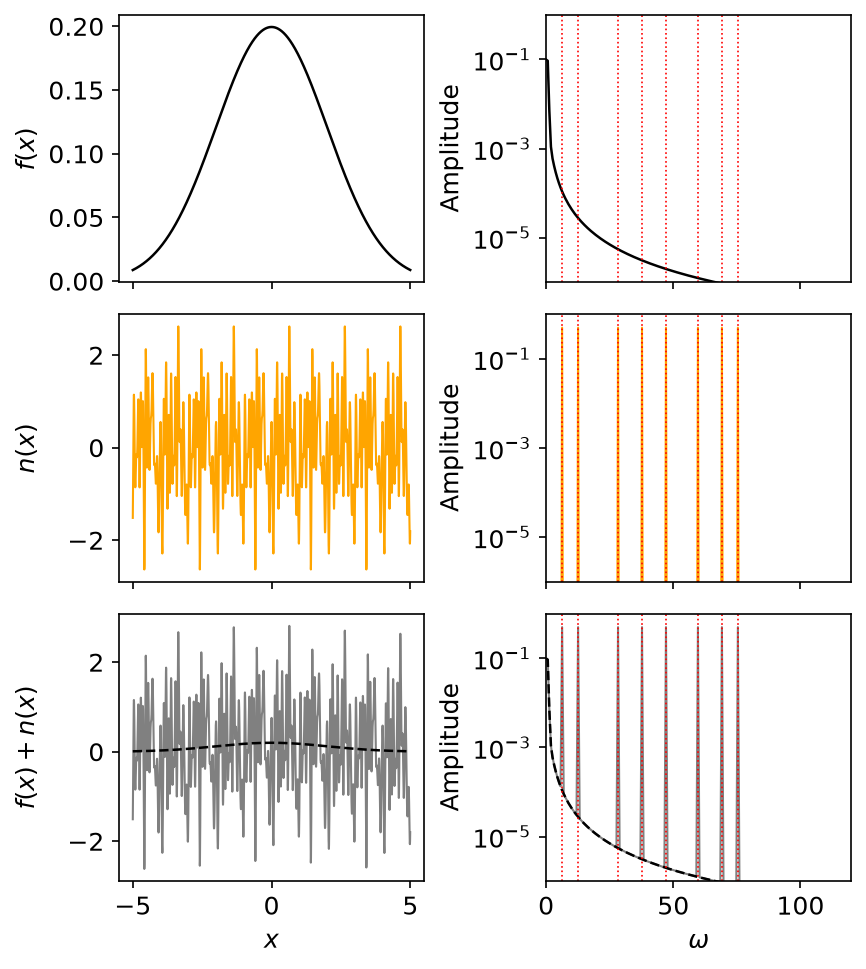

In [8]:
# Plotting: the signals (left) and their Fourier spectra (right).
# Rows from top to bottom: the Gaussian, the noise, and the Gaussian with noise (with the clean Gaussian dashed on top)
OMEGA_MAX = 120

with plt.rc_context(REPORT_STYLE):
    # sharex='col': the left column shares the x axis, the right column shares the omega axis
    fig, axs = plt.subplots(3, 2, figsize=(6.3, 7.5), sharex='col',
                            gridspec_kw=dict(hspace=0.12, wspace=0.4))

    # --- Left column: the signals
    axs[0, 0].plot(x_gaussian_linspace, gaussian, color='black', lw=1.2)
    axs[0, 0].set_ylabel(r'$f(x)$')

    axs[1, 0].plot(x_gaussian_linspace, noise, color='orange', lw=1.0)
    axs[1, 0].set_ylabel(r'$n(x)$')

    axs[2, 0].plot(x_gaussian_linspace, noisy_gaussian, color='grey', lw=1.0)
    axs[2, 0].plot(x_gaussian_linspace, gaussian, color='black', lw=1.2, linestyle='--')    # the clean Gaussian, for comparison
    axs[2, 0].set_ylabel(r'$f(x) + n(x)$')
    axs[2, 0].set_xlabel(r'$x$')

    # --- Right column: the Fourier spectra
    axs[0, 1].plot(omega_combined, amplitude_gaussian, color='black', lw=1.2)
    axs[1, 1].plot(omega_combined, amplitude_noise, color='orange', lw=1.0)
    axs[2, 1].plot(omega_combined, amplitude_combined, color='grey', lw=1.0)
    axs[2, 1].plot(omega_combined, amplitude_gaussian, color='black', lw=1.2, linestyle='--')   # spectrum of the clean Gaussian
    axs[2, 1].set_xlabel(r'$\omega$')

    for ax in axs[:, 1]:                          # only the spectra, not the signals
        ax.set_yscale('log')                      # log scale, so small and large amplitudes are both visible
        ax.set_ylim(1e-6, 1)
        ax.set_yticks([1e-5, 1e-3, 1e-1])         # no tick labels at the edges, so they do not run into the next row
        ax.set_ylabel('Amplitude')
        for omega_mode in FREQUENCIES:            # mark the frequencies of the sine waves
            ax.axvline(omega_mode, color='red', linestyle=':', linewidth=0.8)

    axs[0, 1].set_xlim(0, OMEGA_MAX)              # shared within the column, so this sets all three spectra
    fig.align_ylabels(axs[:, 0])
    fig.align_ylabels(axs[:, 1])

    fig.savefig('Plots/Toy/Sine_noise_gaussian.pdf')            # vector version, for LaTeX
    plt.show()


### Training Lipschitz networks on the sine noise

In [9]:
# Training Lipschitz networks on the noisy Gaussian, for the same L values as before
L_true_gaussian = gaussian_lipschitz_constant(SIGMA)
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true_gaussian:.4f}")
L_true_noise = np.max(np.abs(np.gradient(noisy_gaussian, x_gaussian_linspace)))  # approximate Lipschitz constant of the noisy function
print(f"Lipschitz constant of the noisy Gaussian function: {L_true_noise:.4f}")
L_true = max(L_true_gaussian, L_true_noise)


Lipschitz constant of the Gaussian function with sigma=2.0: 0.0605
Lipschitz constant of the noisy Gaussian function: 141.9211


In [10]:
# Training Lipschitz networks on the noisy Gaussian
from Toy_utils import train_full_batch   # plain full-batch Adam training with MSE loss (see Toy_utils.py)

# HYPERPARAMETERS
L_VALUES = np.logspace(np.log10(L_true_gaussian*0.85), np.log10(L_true), 4)   # Lipschitz constants to compare. The Gaussian needs 0.06 and the sine waves needs drastically more
SEEDS = [0, 1, 2]                  # several seeds per L, to see how much the result varies between runs
HIDDEN_DIM = 64                    # wide enough that an unconstrained network can fit the sine waves
N_GROUPS = 8
DEPTH = 5
STEPS = 6000                       # number of full-batch training steps
LEARNING_RATE = 3e-3

# Data as torch tensors with shape (N, 1), which is what the networks expect
x_tensor = torch.tensor(x_gaussian_linspace, dtype=torch.float32).unsqueeze(-1)
y_tensor = torch.tensor(noisy_gaussian, dtype=torch.float32).unsqueeze(-1)

# Everything is stored per L and per seed:
#   models[L][seed]      = the trained network (kept, so we can compute slopes later)
#   predictions[L][seed] = the network output on x, as a numpy array
models = {}
predictions = {}

for L in L_VALUES:
    models[L] = {}
    predictions[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)    # same seed gives the same starting weights, so every run can be reproduced
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1,
                               n_groups=N_GROUPS, depth=DEPTH, lipschitz_bound=L)
        train_full_batch(model, x_tensor, y_tensor, steps=STEPS, lr=LEARNING_RATE) # NOTE: COSINE ANNEALING HERE

        models[L][seed] = model
        with torch.no_grad():
            predictions[L][seed] = model(x_tensor).numpy().ravel()

        mse_noisy = np.mean((predictions[L][seed] - noisy_gaussian) ** 2)   # how well it fits the training data
        mse_clean = np.mean((predictions[L][seed] - gaussian) ** 2)         # how close it gets to the clean Gaussian
        print(f"L = {L:.3e}, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")

# Unconstrained reference: same size and training, no Lipschitz bound
models_unconstrained = {}
predictions_unconstrained = {}

for seed in SEEDS:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)
    train_full_batch(model, x_tensor, y_tensor, steps=STEPS, lr=LEARNING_RATE)

    models_unconstrained[seed] = model
    with torch.no_grad():
        predictions_unconstrained[seed] = model(x_tensor).numpy().ravel()

    mse_noisy = np.mean((predictions_unconstrained[seed] - noisy_gaussian) ** 2)
    mse_clean = np.mean((predictions_unconstrained[seed] - gaussian) ** 2)
    print(f"Unconstrained, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")


L = 5.142e-02, seed 0: MSE to the noisy data = 9.97e-01, MSE to the clean Gaussian = 5.27e-04
L = 5.142e-02, seed 1: MSE to the noisy data = 9.97e-01, MSE to the clean Gaussian = 7.10e-04
L = 5.142e-02, seed 2: MSE to the noisy data = 9.97e-01, MSE to the clean Gaussian = 6.69e-04
L = 7.213e-01, seed 0: MSE to the noisy data = 9.37e-01, MSE to the clean Gaussian = 1.03e-02
L = 7.213e-01, seed 1: MSE to the noisy data = 9.35e-01, MSE to the clean Gaussian = 9.75e-03
L = 7.213e-01, seed 2: MSE to the noisy data = 9.36e-01, MSE to the clean Gaussian = 9.19e-03
L = 1.012e+01, seed 0: MSE to the noisy data = 7.41e-01, MSE to the clean Gaussian = 1.80e-01
L = 1.012e+01, seed 1: MSE to the noisy data = 7.21e-01, MSE to the clean Gaussian = 2.16e-01
L = 1.012e+01, seed 2: MSE to the noisy data = 7.39e-01, MSE to the clean Gaussian = 1.94e-01
L = 1.419e+02, seed 0: MSE to the noisy data = 6.34e-01, MSE to the clean Gaussian = 2.97e-01
L = 1.419e+02, seed 1: MSE to the noisy data = 6.69e-01, MSE

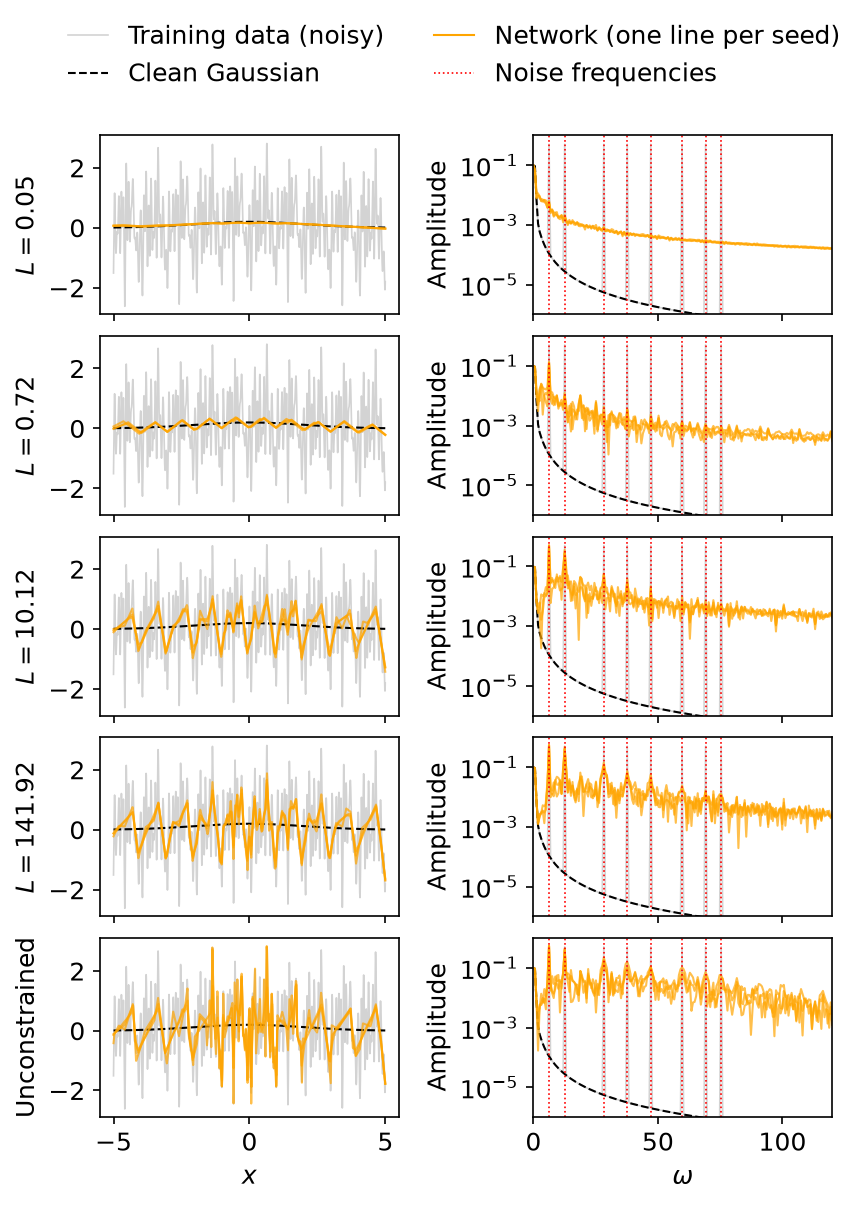

In [17]:
# Report figure: all networks in one figure. One row per network, the fit on the left and its Fourier spectrum on the right.
# Uses REPORT_STYLE from the floor-fit plot cell above.

OMEGA_MAX = 120   # highest frequency shown in the spectra

# The rows of the figure: the Lipschitz networks first, then the unconstrained reference
row_predictions = []
row_names = []
row_L = []
for L in L_VALUES:
    row_predictions.append(predictions[L])
    row_names.append(f'$L = {L:.2f}$')
    row_L.append(L)
row_predictions.append(predictions_unconstrained)
row_names.append('Unconstrained')
row_L.append(None)                 # no cutoff line for the unconstrained network

# The predicted cutoff omega = L / A is only one frequency when all the sine waves have the same amplitude A
equal_amplitudes = len(set(AMPLITUDES)) == 1

# Spectra of the training data and the clean Gaussian (the same in every row)
omega, amplitude_noisy = fourier_spectrum(x_gaussian_linspace, noisy_gaussian)
omega, amplitude_gaussian = fourier_spectrum(x_gaussian_linspace, gaussian)

n_rows = len(row_predictions)
with plt.rc_context(REPORT_STYLE):
    # 1.7 inches per row, and a wide gap between the columns, so the 'Amplitude' label does not touch the left panels
    fig, axs = plt.subplots(n_rows, 2, figsize=(6.3, 1.7 * n_rows), sharex='col',
                            gridspec_kw=dict(hspace=0.12, wspace=0.45))

    for i in range(n_rows):
        # --- Left: the functions
        ax = axs[i, 0]
        ax.plot(x_gaussian_linspace, noisy_gaussian, color='lightgrey', lw=0.8)
        ax.plot(x_gaussian_linspace, gaussian, color='black', lw=1.0, linestyle='--')
        for prediction in row_predictions[i].values():          # one line per seed
            ax.plot(x_gaussian_linspace, prediction, color='orange', alpha=0.7, lw=1.0)
        ax.set_ylabel(row_names[i])                               # network name at the start of the row

        # --- Right: the spectra
        ax = axs[i, 1]
        ax.plot(omega, amplitude_noisy, color='lightgrey', lw=0.8)
        ax.plot(omega, amplitude_gaussian, color='black', lw=1.0, linestyle='--')
        for prediction in row_predictions[i].values():
            omega_prediction, amplitude_prediction = fourier_spectrum(x_gaussian_linspace, prediction)
            ax.plot(omega_prediction, amplitude_prediction, color='orange', alpha=0.7, lw=1.0)
        for omega_mode in FREQUENCIES:                           # frequencies of the sine waves
            ax.axvline(omega_mode, color='red', linestyle=':', linewidth=0.8)
        #if equal_amplitudes and row_L[i] is not None:            # predicted cutoff omega = L / A
            #ax.axvline(row_L[i] / AMPLITUDES[0], color='blue', linewidth=1.0)
        ax.set_yscale('log')
        ax.set_ylim(1e-6, 1)
        ax.set_yticks([1e-5, 1e-3, 1e-1])                        # no tick labels at the edges, so they do not run into the next row
        ax.set_xlim(0, OMEGA_MAX)
        ax.set_ylabel('Amplitude')

    axs[-1, 0].set_xlabel(r'$x$')
    axs[-1, 1].set_xlabel(r'$\omega$')
    fig.align_ylabels(axs[:, 0])
    fig.align_ylabels(axs[:, 1])

    # One shared legend above the figure
    legend_lines = [plt.Line2D([], [], color='lightgrey', lw=0.8),
                    plt.Line2D([], [], color='black', lw=1.0, linestyle='--'),
                    plt.Line2D([], [], color='orange', lw=1.0),
                    plt.Line2D([], [], color='red', linestyle=':', lw=0.8)]
    legend_labels = ['Training data (noisy)', 'Clean Gaussian', 'Network (one line per seed)', 'Noise frequencies']
    #if equal_amplitudes:
        #legend_lines.append(plt.Line2D([], [], color='blue', lw=1.0))
        #legend_labels.append(r'Predicted cutoff $L/A$')
    fig.legend(legend_lines, legend_labels, loc='lower center', bbox_to_anchor=(0.5, 0.9), ncol=2, frameon=False)

    fig.savefig('Plots/Toy/sine_noise_fits_and_spectra.pdf')
    plt.show()


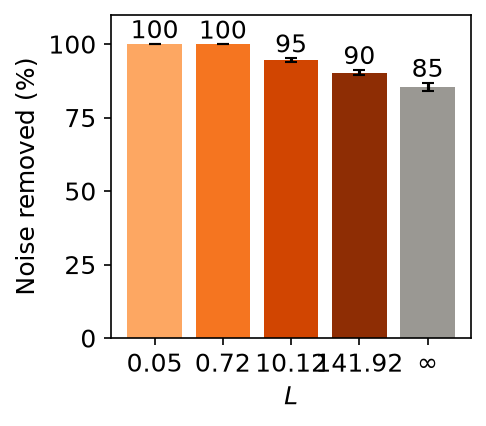

In [19]:
# Bar plot of the noise removed by each network (report format).
# Lipschitz networks in orange (light -> dark = small -> large L), the unconstrained network in grey,
# labelled L = infinity since it has no bound on the slope. Error bars: the spread (std) over the seeds.
from Toy_utils import noise_removed      # noise_removed(prediction, clean, noise): share of the noise energy not copied
C_REF = "#9a9893"   # grey for the unconstrained reference, as in the other network plots

# Noise removed (in %) for every network: mean and spread over the seeds
bar_names = []
removed_bar_mean = []
removed_bar_std = []

for L in L_VALUES:
    removed = []
    for seed in SEEDS:
        removed.append(100 * noise_removed(predictions[L][seed], gaussian, noise))
    bar_names.append(f'{L:.2f}')
    removed_bar_mean.append(np.mean(removed))
    removed_bar_std.append(np.std(removed))

removed = []
for seed in SEEDS:
    removed.append(100 * noise_removed(predictions_unconstrained[seed], gaussian, noise))
bar_names.append(r'$\infty$')
removed_bar_mean.append(np.mean(removed))
removed_bar_std.append(np.std(removed))

# Orange shades for the Lipschitz networks, grey for the unconstrained one
bar_colors = list(plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_VALUES))))
bar_colors.append(C_REF)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    positions = np.arange(len(bar_names))
    ax.bar(positions, removed_bar_mean, yerr=removed_bar_std, capsize=3, color=bar_colors)

    # Write the value on top of each bar, just above its error bar
    for i in range(len(bar_names)):
        ax.text(positions[i], removed_bar_mean[i] + removed_bar_std[i] + 2, f'{removed_bar_mean[i]:.0f}', ha='center')

    ax.set_xticks(positions)
    ax.set_xticklabels(bar_names)
    ax.set_xlabel(r'$L$')
    ax.set_ylabel('Noise removed (%)')
    ax.set_ylim(0, 110)                     # room above 100 % for the numbers on the bars
    ax.set_yticks([0, 25, 50, 75, 100])

    fig.savefig('Plots/Toy/sine_noise_removed.pdf')            # vector version, for LaTeX
    #fig.savefig('Plots/Toy/sine_noise_removed.png', dpi=300)   # high-resolution picture, for slides
    plt.show()


In [20]:
# Investigating the effect of the Lipschitz bound on the noise removal and the accuracy.
# This cell only trains and stores the predictions. The measures are calculated in the plotting cells below,
# so they can be changed without training again.

L_RATIO = np.logspace(-1.5, 0, 12)   # L / L_max, logarithmic so the small L (where the waves start to be clipped) are resolved
SEEDS = [0, 1, 2]                    # several seeds per L, to see how much the result varies between runs

L_gaussian = gaussian_lipschitz_constant(SIGMA)
L_gaussian_noisy = np.max(np.abs(np.gradient(noisy_gaussian, x_gaussian_linspace)))  # approximate Lipschitz constant of the noisy function
L_max = max(L_gaussian, L_gaussian_noisy)

print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_gaussian:.4f}")
print(f"Lipschitz constant of the noisy Gaussian function: {L_gaussian_noisy:.4f}")
print(f"Maximum Lipschitz constant to consider: {L_max:.4f}")

# Training data: the noisy Gaussian from the noise cell
x_tensor = torch.tensor(x_gaussian_linspace, dtype=torch.float32).unsqueeze(-1)
y_tensor = torch.tensor(noisy_gaussian, dtype=torch.float32).unsqueeze(-1)

# Everything is stored per L and per seed:
#   predictions_scan[L][seed]        = output of the Lipschitz network on x_gaussian_linspace
#   predictions_scan_unconstrained[seed] = output of the unconstrained network
L_scan = L_RATIO * L_max
predictions_scan = {}

for L in L_scan:
    predictions_scan[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1,
                               n_groups=N_GROUPS, depth=DEPTH, lipschitz_bound=L)
        train_full_batch(model, x_tensor, y_tensor, steps=STEPS, lr=LEARNING_RATE)

        with torch.no_grad():
            predictions_scan[L][seed] = model(x_tensor).numpy().ravel()
    print(f"L = {L:.4f} (L / L_max = {L / L_max:.3f}): trained {len(SEEDS)} seeds")

# Unconstrained reference: same size and training, no Lipschitz bound
predictions_scan_unconstrained = {}
for seed in SEEDS:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)
    train_full_batch(model, x_tensor, y_tensor, steps=STEPS, lr=LEARNING_RATE)

    with torch.no_grad():
        predictions_scan_unconstrained[seed] = model(x_tensor).numpy().ravel()
print(f"Unconstrained: trained {len(SEEDS)} seeds")


Lipschitz constant of the Gaussian function with sigma=2.0: 0.0605
Lipschitz constant of the noisy Gaussian function: 141.9211
Maximum Lipschitz constant to consider: 141.9211
L = 4.4879 (L / L_max = 0.032): trained 3 seeds
L = 6.1434 (L / L_max = 0.043): trained 3 seeds
L = 8.4096 (L / L_max = 0.059): trained 3 seeds
L = 11.5117 (L / L_max = 0.081): trained 3 seeds
L = 15.7580 (L / L_max = 0.111): trained 3 seeds
L = 21.5707 (L / L_max = 0.152): trained 3 seeds
L = 29.5276 (L / L_max = 0.208): trained 3 seeds
L = 40.4196 (L / L_max = 0.285): trained 3 seeds
L = 55.3294 (L / L_max = 0.390): trained 3 seeds
L = 75.7390 (L / L_max = 0.534): trained 3 seeds
L = 103.6772 (L / L_max = 0.731): trained 3 seeds
L = 141.9211 (L / L_max = 1.000): trained 3 seeds
Unconstrained: trained 3 seeds


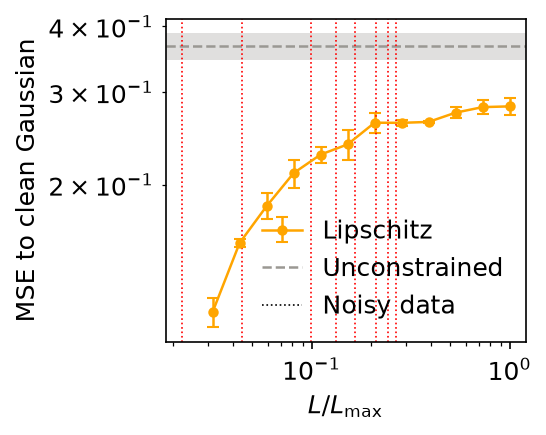

In [33]:
# Accuracy of the networks as a function of L: the MSE to the CLEAN Gaussian (lower = more accurate).
# Error bars: the spread (std) over the seeds. The unconstrained network is the baseline.
C_REF = "#9a9893"   # grey for the unconstrained reference, as in the other network plots

# MSE to the clean Gaussian for every L: mean and spread over the seeds
mse_scan_mean = []
mse_scan_std = []
for L in L_scan:
    mse = []
    for seed in SEEDS:
        mse.append(np.mean((predictions_scan[L][seed] - gaussian) ** 2))
    mse_scan_mean.append(np.mean(mse))
    mse_scan_std.append(np.std(mse))

# The same for the unconstrained network
mse = []
for seed in SEEDS:
    mse.append(np.mean((predictions_scan_unconstrained[seed] - gaussian) ** 2))
mse_unconstrained_mean = np.mean(mse)
mse_unconstrained_std = np.std(mse)

# The MSE of the noisy training data itself: what you get by not removing any noise at all
mse_data = np.mean(noise**2)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)

    # Lipschitz networks: mean over seeds with error bars
    lipschitz_line = ax.errorbar(L_RATIO, mse_scan_mean, yerr=mse_scan_std, fmt='o-', color='orange',
                                 lw=1.2, markersize=4, capsize=3, label='Lipschitz')

    # Unconstrained network: one value (it has no L), a horizontal line with its spread as a band
    unconstrained_line = ax.axhline(mse_unconstrained_mean, color=C_REF, lw=1.2, linestyle='--', label='Unconstrained')
    ax.axhspan(mse_unconstrained_mean - mse_unconstrained_std, mse_unconstrained_mean + mse_unconstrained_std,
               color=C_REF, alpha=0.3, lw=0)

    # The noisy training data itself, for reference
    #data_line = ax.axhline(mse_data, color='black', lw=0.8, linestyle=':', label='Noisy data')

    # Where each sine wave starts to be clipped: the slope it needs, A * omega, relative to L_max
    for A, omega_mode in zip(AMPLITUDES, FREQUENCIES):
        ax.axvline(A * omega_mode / L_max, color='red', linestyle=':', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$L / L_\mathrm{max}$')
    ax.set_ylabel('MSE to clean Gaussian')
    ax.legend(handles=[lipschitz_line, unconstrained_line], frameon=False)

    fig.savefig('Plots/Toy/sine_noise_mse_vs_L.pdf')
    plt.show()


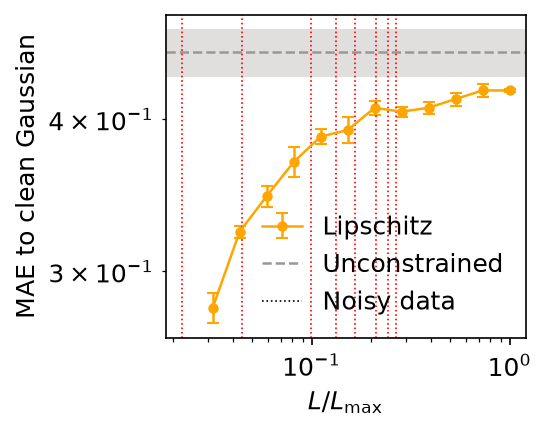

In [32]:
# Accuracy of the networks as a function of L: the MAE (mean absolute error) to the CLEAN Gaussian (lower = more accurate).
# Error bars: the spread (std) over the seeds. The unconstrained network is the baseline.
C_REF = "#9a9893"   # grey for the unconstrained reference, as in the other network plots

# MAE to the clean Gaussian for every L: mean and spread over the seeds
mae_scan_mean = []
mae_scan_std = []
for L in L_scan:
    mae = []
    for seed in SEEDS:
        mae.append(np.mean(np.abs(predictions_scan[L][seed] - gaussian)))
    mae_scan_mean.append(np.mean(mae))
    mae_scan_std.append(np.std(mae))

# The same for the unconstrained network (one value, it has no L)
mae = []
for seed in SEEDS:
    mae.append(np.mean(np.abs(predictions_scan_unconstrained[seed] - gaussian)))
mae_unconstrained_mean = np.mean(mae)
mae_unconstrained_std = np.std(mae)

# The MAE of the noisy training data itself: what you get by not removing any noise at all
mae_data = np.mean(np.abs(noise))

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)

    # Lipschitz networks: mean over seeds with error bars
    lipschitz_line = ax.errorbar(L_RATIO, mae_scan_mean, yerr=mae_scan_std, fmt='o-', color='orange',
                                 lw=1.2, markersize=4, capsize=3, label='Lipschitz')

    # Unconstrained network: one value (it has no L), a horizontal line with its spread as a band
    unconstrained_line = ax.axhline(mae_unconstrained_mean, color=C_REF, lw=1.2, linestyle='--', label='Unconstrained')
    ax.axhspan(mae_unconstrained_mean - mae_unconstrained_std, mae_unconstrained_mean + mae_unconstrained_std,
               color=C_REF, alpha=0.3, lw=0)

    # The noisy training data itself, for reference
    #data_line = ax.axhline(mae_data, color='black', lw=0.8, linestyle=':', label='Noisy data')

    # Where each sine wave starts to be clipped: the slope it needs, A * omega, relative to L_max
    for A, omega_mode in zip(AMPLITUDES, FREQUENCIES):
        ax.axvline(A * omega_mode / L_max, color='red', linestyle=':', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$L / L_\mathrm{max}$')
    ax.set_ylabel('MAE to clean Gaussian')
    ax.legend(handles=[lipschitz_line, unconstrained_line], frameon=False)

    fig.savefig('Plots/Toy/sine_noise_mae_vs_L.pdf')
    plt.show()


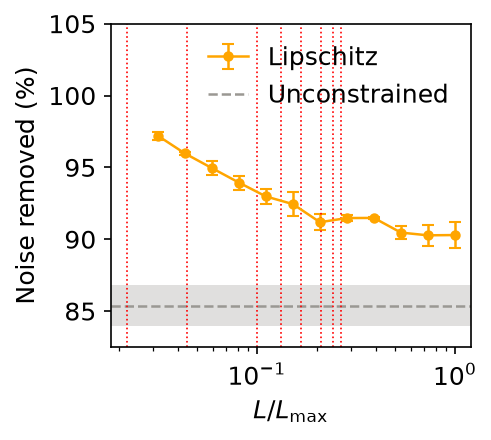

In [27]:
# Noise removed as a function of L, with the unconstrained network as reference.
# Error bars: the spread (std) over the seeds.
from Toy_utils import noise_removed      # noise_removed(prediction, clean, noise)
C_REF = "#9a9893"

# Noise removed (in %) for every L: mean and spread over the seeds
removed_scan_mean = []
removed_scan_std = []
for L in L_scan:
    removed = []
    for seed in SEEDS:
        removed.append(100 * noise_removed(predictions_scan[L][seed], gaussian, noise))
    removed_scan_mean.append(np.mean(removed))
    removed_scan_std.append(np.std(removed))

# The same for the unconstrained network
removed = []
for seed in SEEDS:
    removed.append(100 * noise_removed(predictions_scan_unconstrained[seed], gaussian, noise))
removed_unconstrained_mean = np.mean(removed)
removed_unconstrained_std = np.std(removed)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)

    # Lipschitz networks: mean over seeds with error bars
    lipschitz_line = ax.errorbar(L_RATIO, removed_scan_mean, yerr=removed_scan_std, fmt='o-', color='orange',
                                 lw=1.2, markersize=4, capsize=3, label='Lipschitz')

    # Unconstrained network: a horizontal line with its spread as a band
    unconstrained_line = ax.axhline(removed_unconstrained_mean, color=C_REF, lw=1.2, linestyle='--', label='Unconstrained')
    ax.axhspan(removed_unconstrained_mean - removed_unconstrained_std, removed_unconstrained_mean + removed_unconstrained_std,
               color=C_REF, alpha=0.3, lw=0)

    # Where each sine wave starts to be clipped: the slope it needs, A * omega, relative to L_max
    for A, omega_mode in zip(AMPLITUDES, FREQUENCIES):
        ax.axvline(A * omega_mode / L_max, color='red', linestyle=':', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_ylim(removed_unconstrained_mean-2*removed_unconstrained_std, 105)
    ax.set_xlabel(r'$L / L_\mathrm{max}$')
    ax.set_ylabel('Noise removed (%)')
    ax.set_yscale('linear')
    ax.legend(handles=[lipschitz_line, unconstrained_line], frameon=False)

    fig.savefig('Plots/Toy/sine_noise_removed_vs_L.pdf')
    plt.show()


IDEA: make a new run, the run should be a log scan over the L values going a bit further than the true Lipschitz constant of the full function. Calculate and store the individual MSE for the runs, as well as the noise removal in percentage. Then plot the MSE and Noise removal as a function of the L values. Seeding the runs with three runs each gives us a mean an std for both. These can possibly be used to make a width of the plots

# White noise response
The same pipeline as the sine-wave section: the same Gaussian, grid, network size, training and evaluation. The only difference is the noise. Instead of a few sine waves, every point gets its own independent random number (white noise). The noise level is set so that the white noise has the *same power* (mean squared noise) as the sine-wave noise above, so the two sections can be compared directly.

White noise has no particular frequency: its energy is spread evenly over all frequencies, up to the highest one the grid can show. Most of it is therefore very fast and needs slopes far above the slope of the Gaussian. Only the slowest part of the noise has slopes small enough to pass the bound.

Uses `REPORT_STYLE` and `PANEL_SIZE` from the floor-fit plot cell, and `fourier_spectrum`, `L_RATIO`, `SEEDS` and the network settings (`HIDDEN_DIM`, `N_GROUPS`, `DEPTH`, `STEPS`, `LEARNING_RATE`) from the sine-wave section, so run that section first. All results get their own names ending in `_white`, so the sine-wave results are not overwritten.

In [34]:
# White noise generation, on the same grid and Gaussian as the sine-wave noise
NOISE_SEED = 0                              # fixed seed, so the same noise pattern is used every time the cell is run
NOISE_STD = np.sqrt(np.mean(noise ** 2))    # same noise power (mean squared noise) as the sine-wave noise above

# The x grid and the clean Gaussian: the same as in the sine-wave section
x_white = np.linspace(X_MIN, X_MAX, N, endpoint=False)
gaussian_white = np.exp(-0.5 * (x_white / SIGMA) ** 2) / (SIGMA * np.sqrt(2 * np.pi))

# White noise: an independent random number at every point
rng = np.random.default_rng(NOISE_SEED)
white_noise = NOISE_STD * rng.standard_normal(N)
noisy_gaussian_white = gaussian_white + white_noise

print(f"Noise standard deviation: {NOISE_STD:.4f} (mean squared noise {np.mean(white_noise ** 2):.3e}, "
      f"sine-wave noise {np.mean(noise ** 2):.3e})")
print(f"Largest slope of the Gaussian: {gaussian_lipschitz_constant(SIGMA):.4f}")
print(f"Largest slope of the noisy data: {np.max(np.abs(np.gradient(noisy_gaussian_white, x_white))):.1f}")

# Calculating the fourier spectra
omega_white, amplitude_gaussian_white = fourier_spectrum(x_white, gaussian_white)
omega_white, amplitude_noise_white = fourier_spectrum(x_white, white_noise)
omega_white, amplitude_combined_white = fourier_spectrum(x_white, noisy_gaussian_white)

Noise standard deviation: 1.0000 (mean squared noise 1.001e+00, sine-wave noise 1.000e+00)
Largest slope of the Gaussian: 0.0605
Largest slope of the noisy data: 508.2


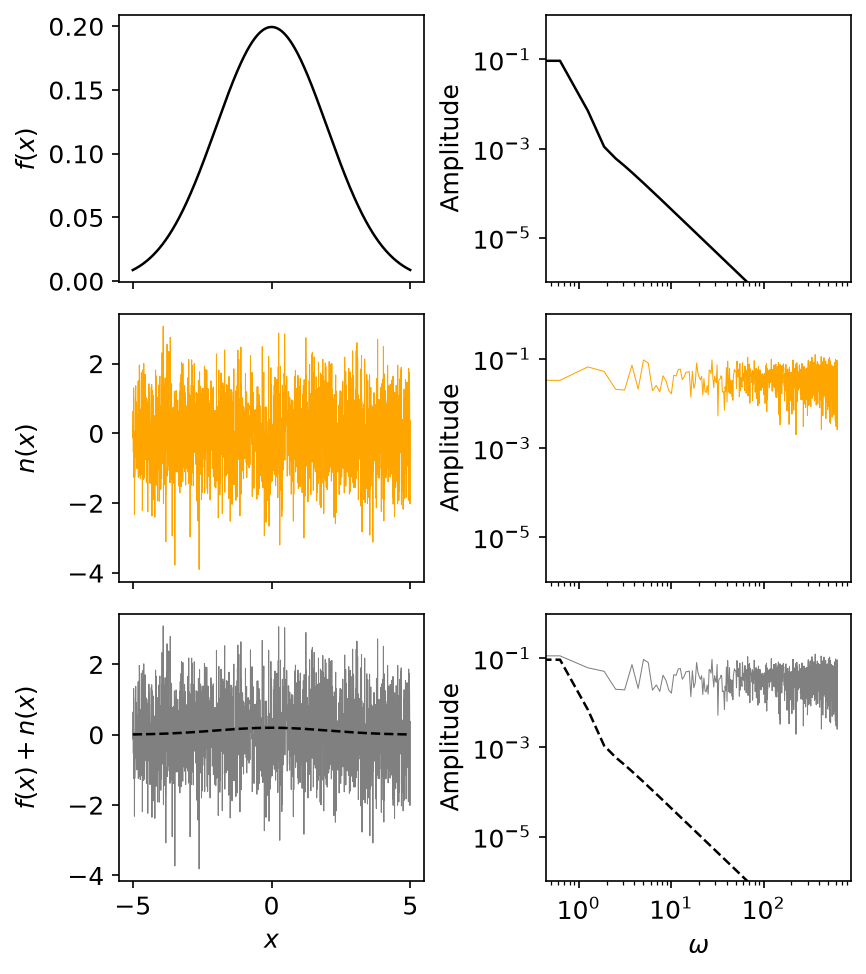

In [35]:
# Plotting: the signals (left) and their Fourier spectra (right), for the white noise.
# Rows from top to bottom: the Gaussian, the noise, and the Gaussian with noise (with the clean Gaussian dashed on top)
# The frequency axis is logarithmic, since white noise covers all frequencies up to the highest one on the grid.

with plt.rc_context(REPORT_STYLE):
    # sharex='col': the left column shares the x axis, the right column shares the omega axis
    fig, axs = plt.subplots(3, 2, figsize=(6.3, 7.5), sharex='col',
                            gridspec_kw=dict(hspace=0.12, wspace=0.4))

    # --- Left column: the signals
    axs[0, 0].plot(x_white, gaussian_white, color='black', lw=1.2)
    axs[0, 0].set_ylabel(r'$f(x)$')

    axs[1, 0].plot(x_white, white_noise, color='orange', lw=0.5)       # thin, since the noise is very dense
    axs[1, 0].set_ylabel(r'$n(x)$')

    axs[2, 0].plot(x_white, noisy_gaussian_white, color='grey', lw=0.5)
    axs[2, 0].plot(x_white, gaussian_white, color='black', lw=1.2, linestyle='--')    # the clean Gaussian, for comparison
    axs[2, 0].set_ylabel(r'$f(x) + n(x)$')
    axs[2, 0].set_xlabel(r'$x$')

    # --- Right column: the Fourier spectra
    axs[0, 1].plot(omega_white, amplitude_gaussian_white, color='black', lw=1.2)
    axs[1, 1].plot(omega_white, amplitude_noise_white, color='orange', lw=0.5)
    axs[2, 1].plot(omega_white, amplitude_combined_white, color='grey', lw=0.5)
    axs[2, 1].plot(omega_white, amplitude_gaussian_white, color='black', lw=1.2, linestyle='--')   # spectrum of the clean Gaussian
    axs[2, 1].set_xlabel(r'$\omega$')

    for ax in axs[:, 1]:                          # only the spectra, not the signals
        ax.set_xscale('log')                      # white noise covers all frequencies
        ax.set_yscale('log')                      # log scale, so small and large amplitudes are both visible
        ax.set_ylim(1e-6, 1)
        ax.set_yticks([1e-5, 1e-3, 1e-1])         # no tick labels at the edges, so they do not run into the next row
        ax.set_ylabel('Amplitude')

    fig.align_ylabels(axs[:, 0])
    fig.align_ylabels(axs[:, 1])

    fig.savefig('Plots/Toy/White_noise_gaussian.pdf')            # vector version, for LaTeX
    plt.show()

### Training Lipschitz networks on the white noise

In [36]:
# Training Lipschitz networks on the Gaussian with white noise (same networks and settings as the sine-wave section)
from Toy_utils import train_full_batch   # plain full-batch Adam training with MSE loss (see Toy_utils.py)

L_true_gaussian_white = gaussian_lipschitz_constant(SIGMA)
L_true_noise_white = np.max(np.abs(np.gradient(noisy_gaussian_white, x_white)))   # approximate Lipschitz constant of the noisy function
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true_gaussian_white:.4f}")
print(f"Lipschitz constant of the noisy Gaussian function: {L_true_noise_white:.4f}")

# Lipschitz constants to compare: from just below the slope of the Gaussian up to the slope of the noisy data,
# chosen in the same way as in the sine-wave section
L_VALUES_WHITE = np.logspace(np.log10(L_true_gaussian_white * 0.85), np.log10(L_true_noise_white), 4)

# Data as torch tensors with shape (N, 1), which is what the networks expect
x_white_tensor = torch.tensor(x_white, dtype=torch.float32).unsqueeze(-1)
y_white_tensor = torch.tensor(noisy_gaussian_white, dtype=torch.float32).unsqueeze(-1)

# Everything is stored per L and per seed:
#   predictions_white[L][seed]          = output of the Lipschitz network on x_white, as a numpy array
#   predictions_white_unconstrained[seed] = output of the unconstrained network
predictions_white = {}

for L in L_VALUES_WHITE:
    predictions_white[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)    # same seed gives the same starting weights, so every run can be reproduced
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1,
                               n_groups=N_GROUPS, depth=DEPTH, lipschitz_bound=L)
        train_full_batch(model, x_white_tensor, y_white_tensor, steps=STEPS, lr=LEARNING_RATE)

        with torch.no_grad():
            predictions_white[L][seed] = model(x_white_tensor).numpy().ravel()

        mse_noisy = np.mean((predictions_white[L][seed] - noisy_gaussian_white) ** 2)   # how well it fits the training data
        mse_clean = np.mean((predictions_white[L][seed] - gaussian_white) ** 2)         # how close it gets to the clean Gaussian
        print(f"L = {L:.3e}, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")

# Unconstrained reference: same size and training, no Lipschitz bound
predictions_white_unconstrained = {}

for seed in SEEDS:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)
    train_full_batch(model, x_white_tensor, y_white_tensor, steps=STEPS, lr=LEARNING_RATE)

    with torch.no_grad():
        predictions_white_unconstrained[seed] = model(x_white_tensor).numpy().ravel()

    mse_noisy = np.mean((predictions_white_unconstrained[seed] - noisy_gaussian_white) ** 2)
    mse_clean = np.mean((predictions_white_unconstrained[seed] - gaussian_white) ** 2)
    print(f"Unconstrained, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")

Lipschitz constant of the Gaussian function with sigma=2.0: 0.0605
Lipschitz constant of the noisy Gaussian function: 508.2407
L = 5.142e-02, seed 0: MSE to the noisy data = 9.98e-01, MSE to the clean Gaussian = 1.43e-03
L = 5.142e-02, seed 1: MSE to the noisy data = 9.98e-01, MSE to the clean Gaussian = 1.39e-03
L = 5.142e-02, seed 2: MSE to the noisy data = 9.98e-01, MSE to the clean Gaussian = 1.38e-03
L = 1.103e+00, seed 0: MSE to the noisy data = 9.77e-01, MSE to the clean Gaussian = 1.51e-02
L = 1.103e+00, seed 1: MSE to the noisy data = 9.79e-01, MSE to the clean Gaussian = 1.51e-02
L = 1.103e+00, seed 2: MSE to the noisy data = 9.77e-01, MSE to the clean Gaussian = 1.61e-02
L = 2.368e+01, seed 0: MSE to the noisy data = 9.52e-01, MSE to the clean Gaussian = 3.75e-02
L = 2.368e+01, seed 1: MSE to the noisy data = 9.52e-01, MSE to the clean Gaussian = 3.78e-02
L = 2.368e+01, seed 2: MSE to the noisy data = 9.54e-01, MSE to the clean Gaussian = 3.54e-02
L = 5.082e+02, seed 0: MSE 

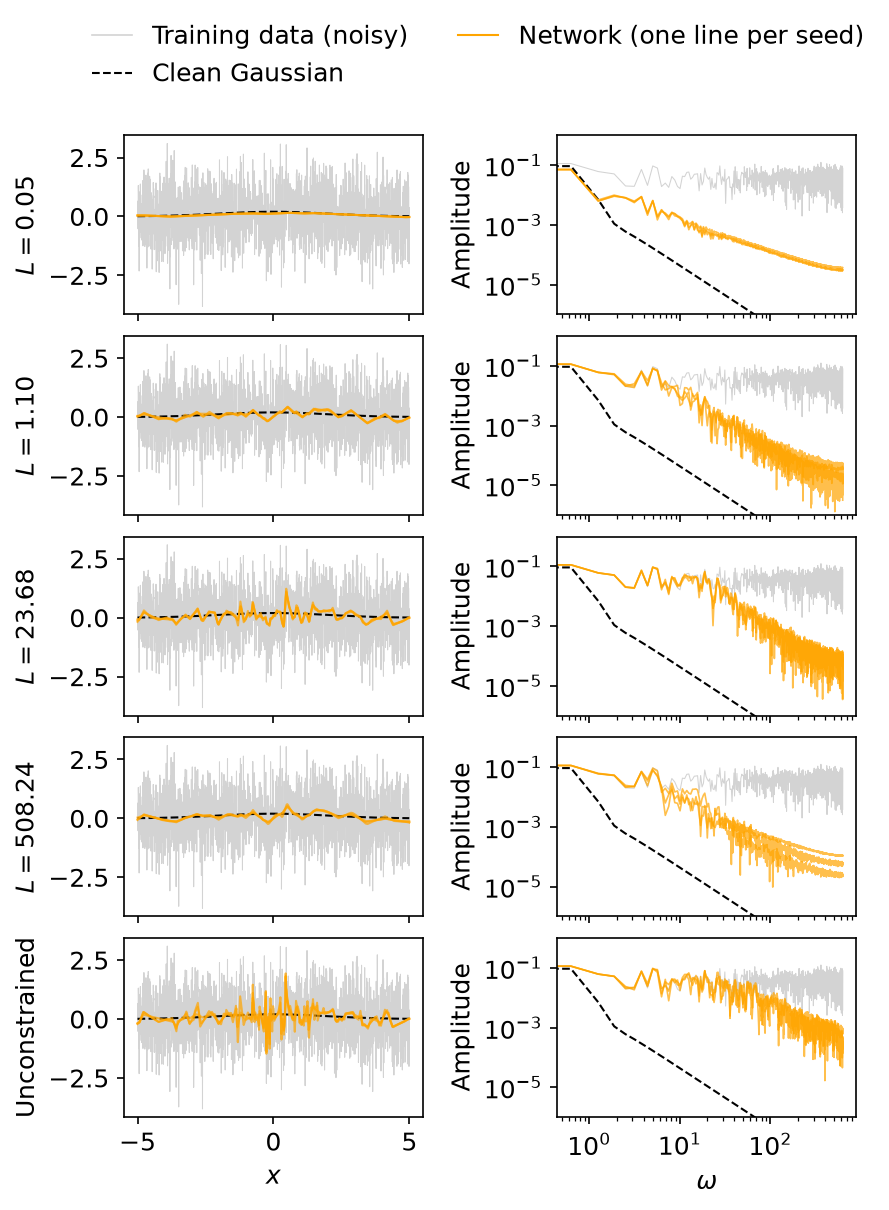

In [37]:
# Report figure for the white noise: all networks in one figure. One row per network, the fit on the left and its
# Fourier spectrum on the right. Uses REPORT_STYLE from the floor-fit plot cell above.

# The rows of the figure: the Lipschitz networks first, then the unconstrained reference
row_predictions = []
row_names = []
for L in L_VALUES_WHITE:
    row_predictions.append(predictions_white[L])
    row_names.append(f'$L = {L:.2f}$')
row_predictions.append(predictions_white_unconstrained)
row_names.append('Unconstrained')

n_rows = len(row_predictions)
with plt.rc_context(REPORT_STYLE):
    # 1.7 inches per row, and a wide gap between the columns, so the 'Amplitude' label does not touch the left panels
    fig, axs = plt.subplots(n_rows, 2, figsize=(6.3, 1.7 * n_rows), sharex='col',
                            gridspec_kw=dict(hspace=0.12, wspace=0.45))

    for i in range(n_rows):
        # --- Left: the functions
        ax = axs[i, 0]
        ax.plot(x_white, noisy_gaussian_white, color='lightgrey', lw=0.5)   # thin, since the noise is very dense
        ax.plot(x_white, gaussian_white, color='black', lw=1.0, linestyle='--')
        for prediction in row_predictions[i].values():                      # one line per seed
            ax.plot(x_white, prediction, color='orange', alpha=0.7, lw=1.0)
        ax.set_ylabel(row_names[i])                                           # network name at the start of the row

        # --- Right: the spectra (both axes logarithmic, since white noise covers all frequencies)
        ax = axs[i, 1]
        ax.plot(omega_white, amplitude_combined_white, color='lightgrey', lw=0.5)
        ax.plot(omega_white, amplitude_gaussian_white, color='black', lw=1.0, linestyle='--')
        for prediction in row_predictions[i].values():
            omega_prediction, amplitude_prediction = fourier_spectrum(x_white, prediction)
            ax.plot(omega_prediction, amplitude_prediction, color='orange', alpha=0.7, lw=0.8)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_ylim(1e-6, 1)
        ax.set_yticks([1e-5, 1e-3, 1e-1])                                    # no tick labels at the edges, so they do not run into the next row
        ax.set_ylabel('Amplitude')

    axs[-1, 0].set_xlabel(r'$x$')
    axs[-1, 1].set_xlabel(r'$\omega$')
    fig.align_ylabels(axs[:, 0])
    fig.align_ylabels(axs[:, 1])

    # One shared legend above the figure
    legend_lines = [plt.Line2D([], [], color='lightgrey', lw=0.8),
                    plt.Line2D([], [], color='black', lw=1.0, linestyle='--'),
                    plt.Line2D([], [], color='orange', lw=1.0)]
    legend_labels = ['Training data (noisy)', 'Clean Gaussian', 'Network (one line per seed)']
    fig.legend(legend_lines, legend_labels, loc='lower center', bbox_to_anchor=(0.5, 0.9), ncol=2, frameon=False)

    fig.savefig('Plots/Toy/white_noise_fits_and_spectra.pdf')
    plt.show()

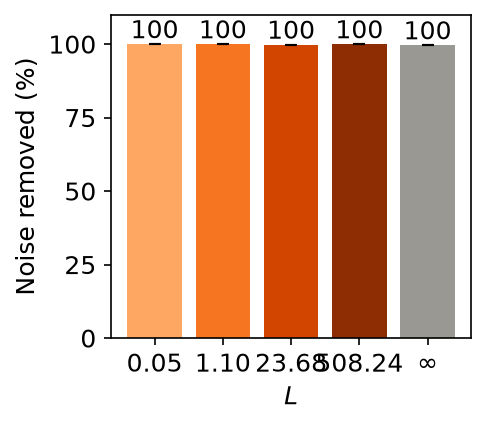

In [38]:
# Bar plot of the white noise removed by each network (report format).
# Lipschitz networks in orange (light -> dark = small -> large L), the unconstrained network in grey,
# labelled L = infinity since it has no bound on the slope. Error bars: the spread (std) over the seeds.
from Toy_utils import noise_removed      # noise_removed(prediction, clean, noise): share of the noise energy not copied
C_REF = "#9a9893"   # grey for the unconstrained reference, as in the other network plots

# Noise removed (in %) for every network: mean and spread over the seeds
bar_names_white = []
removed_bar_white_mean = []
removed_bar_white_std = []

for L in L_VALUES_WHITE:
    removed = []
    for seed in SEEDS:
        removed.append(100 * noise_removed(predictions_white[L][seed], gaussian_white, white_noise))
    bar_names_white.append(f'{L:.2f}')
    removed_bar_white_mean.append(np.mean(removed))
    removed_bar_white_std.append(np.std(removed))

removed = []
for seed in SEEDS:
    removed.append(100 * noise_removed(predictions_white_unconstrained[seed], gaussian_white, white_noise))
bar_names_white.append(r'$\infty$')
removed_bar_white_mean.append(np.mean(removed))
removed_bar_white_std.append(np.std(removed))

# Orange shades for the Lipschitz networks, grey for the unconstrained one
bar_colors = list(plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_VALUES_WHITE))))
bar_colors.append(C_REF)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    positions = np.arange(len(bar_names_white))
    ax.bar(positions, removed_bar_white_mean, yerr=removed_bar_white_std, capsize=3, color=bar_colors)

    # Write the value on top of each bar, just above its error bar
    for i in range(len(bar_names_white)):
        ax.text(positions[i], removed_bar_white_mean[i] + removed_bar_white_std[i] + 2,
                f'{removed_bar_white_mean[i]:.0f}', ha='center')

    ax.set_xticks(positions)
    ax.set_xticklabels(bar_names_white)
    ax.set_xlabel(r'$L$')
    ax.set_ylabel('Noise removed (%)')
    ax.set_ylim(0, 110)                     # room above 100 % for the numbers on the bars
    ax.set_yticks([0, 25, 50, 75, 100])

    fig.savefig('Plots/Toy/white_noise_removed.pdf')            # vector version, for LaTeX
    plt.show()

In [ ]:
# Investigating the effect of the Lipschitz bound on the white noise removal and the accuracy.
# This cell only trains and stores the predictions. The measures are calculated in the plotting cells below,
# so they can be changed without training again. Uses L_RATIO and SEEDS from the sine-wave scan.

L_gaussian_white = gaussian_lipschitz_constant(SIGMA)
L_gaussian_noisy_white = np.max(np.abs(np.gradient(noisy_gaussian_white, x_white)))  # approximate Lipschitz constant of the noisy function
L_max_white = max(L_gaussian_white, L_gaussian_noisy_white)

print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_gaussian_white:.4f}")
print(f"Lipschitz constant of the noisy Gaussian function: {L_gaussian_noisy_white:.4f}")
print(f"Maximum Lipschitz constant to consider: {L_max_white:.4f}")

# Training data: the Gaussian with white noise
x_white_tensor = torch.tensor(x_white, dtype=torch.float32).unsqueeze(-1)
y_white_tensor = torch.tensor(noisy_gaussian_white, dtype=torch.float32).unsqueeze(-1)

# Everything is stored per L and per seed:
#   predictions_scan_white[L][seed]          = output of the Lipschitz network on x_white
#   predictions_scan_white_unconstrained[seed] = output of the unconstrained network
L_scan_white = L_RATIO * L_max_white
predictions_scan_white = {}

for L in L_scan_white:
    predictions_scan_white[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1,
                               n_groups=N_GROUPS, depth=DEPTH, lipschitz_bound=L)
        train_full_batch(model, x_white_tensor, y_white_tensor, steps=STEPS, lr=LEARNING_RATE)

        with torch.no_grad():
            predictions_scan_white[L][seed] = model(x_white_tensor).numpy().ravel()
    print(f"L = {L:.4f} (L / L_max = {L / L_max_white:.3f}): trained {len(SEEDS)} seeds")

# Unconstrained reference: same size and training, no Lipschitz bound
predictions_scan_white_unconstrained = {}
for seed in SEEDS:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)
    train_full_batch(model, x_white_tensor, y_white_tensor, steps=STEPS, lr=LEARNING_RATE)

    with torch.no_grad():
        predictions_scan_white_unconstrained[seed] = model(x_white_tensor).numpy().ravel()
print(f"Unconstrained: trained {len(SEEDS)} seeds")

Lipschitz constant of the Gaussian function with sigma=2.0: 0.0605
Lipschitz constant of the noisy Gaussian function: 508.2407
Maximum Lipschitz constant to consider: 508.2407
L = 16.0720 (L / L_max = 0.032): trained 3 seeds
L = 22.0005 (L / L_max = 0.043): trained 3 seeds
L = 30.1160 (L / L_max = 0.059): trained 3 seeds
L = 41.2250 (L / L_max = 0.081): trained 3 seeds
L = 56.4318 (L / L_max = 0.111): trained 3 seeds
L = 77.2481 (L / L_max = 0.152): trained 3 seeds
L = 105.7429 (L / L_max = 0.208): trained 3 seeds
L = 144.7488 (L / L_max = 0.285): trained 3 seeds


In [ ]:
# Accuracy of the networks as a function of L (white noise): the MSE to the CLEAN Gaussian (lower = more accurate).
# Error bars: the spread (std) over the seeds. The unconstrained network is the baseline.
C_REF = "#9a9893"   # grey for the unconstrained reference, as in the other network plots

# MSE to the clean Gaussian for every L: mean and spread over the seeds
mse_scan_white_mean = []
mse_scan_white_std = []
for L in L_scan_white:
    mse = []
    for seed in SEEDS:
        mse.append(np.mean((predictions_scan_white[L][seed] - gaussian_white) ** 2))
    mse_scan_white_mean.append(np.mean(mse))
    mse_scan_white_std.append(np.std(mse))

# The same for the unconstrained network (one value, it has no L)
mse = []
for seed in SEEDS:
    mse.append(np.mean((predictions_scan_white_unconstrained[seed] - gaussian_white) ** 2))
mse_white_unconstrained_mean = np.mean(mse)
mse_white_unconstrained_std = np.std(mse)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)

    # Lipschitz networks: mean over seeds with error bars
    lipschitz_line = ax.errorbar(L_RATIO, mse_scan_white_mean, yerr=mse_scan_white_std, fmt='o-', color='orange',
                                 lw=1.2, markersize=4, capsize=3, label='Lipschitz')

    # Unconstrained network: one value (it has no L), a horizontal line with its spread as a band
    unconstrained_line = ax.axhline(mse_white_unconstrained_mean, color=C_REF, lw=1.2, linestyle='--', label='Unconstrained')
    ax.axhspan(mse_white_unconstrained_mean - mse_white_unconstrained_std, mse_white_unconstrained_mean + mse_white_unconstrained_std,
               color=C_REF, alpha=0.3, lw=0)

    # White noise has no single frequencies to mark. Instead: the slope of the Gaussian itself. Below this L the bound
    # also cuts into the Gaussian (the floor), so the error must rise there whatever the noise does.
    ax.axvline(L_gaussian_white / L_max_white, color='black', linestyle=':', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$L / L_\mathrm{max}$')
    ax.set_ylabel('MSE to clean Gaussian')
    ax.legend(handles=[lipschitz_line, unconstrained_line], frameon=False)

    fig.savefig('Plots/Toy/white_noise_mse_vs_L.pdf')
    plt.show()

In [ ]:
# Accuracy of the networks as a function of L (white noise): the MAE (mean absolute error) to the CLEAN Gaussian.
# Error bars: the spread (std) over the seeds. The unconstrained network is the baseline.
C_REF = "#9a9893"   # grey for the unconstrained reference, as in the other network plots

# MAE to the clean Gaussian for every L: mean and spread over the seeds
mae_scan_white_mean = []
mae_scan_white_std = []
for L in L_scan_white:
    mae = []
    for seed in SEEDS:
        mae.append(np.mean(np.abs(predictions_scan_white[L][seed] - gaussian_white)))
    mae_scan_white_mean.append(np.mean(mae))
    mae_scan_white_std.append(np.std(mae))

# The same for the unconstrained network (one value, it has no L)
mae = []
for seed in SEEDS:
    mae.append(np.mean(np.abs(predictions_scan_white_unconstrained[seed] - gaussian_white)))
mae_white_unconstrained_mean = np.mean(mae)
mae_white_unconstrained_std = np.std(mae)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)

    # Lipschitz networks: mean over seeds with error bars
    lipschitz_line = ax.errorbar(L_RATIO, mae_scan_white_mean, yerr=mae_scan_white_std, fmt='o-', color='orange',
                                 lw=1.2, markersize=4, capsize=3, label='Lipschitz')

    # Unconstrained network: one value (it has no L), a horizontal line with its spread as a band
    unconstrained_line = ax.axhline(mae_white_unconstrained_mean, color=C_REF, lw=1.2, linestyle='--', label='Unconstrained')
    ax.axhspan(mae_white_unconstrained_mean - mae_white_unconstrained_std, mae_white_unconstrained_mean + mae_white_unconstrained_std,
               color=C_REF, alpha=0.3, lw=0)

    # The slope of the Gaussian itself: below this L the bound also cuts into the Gaussian
    ax.axvline(L_gaussian_white / L_max_white, color='black', linestyle=':', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$L / L_\mathrm{max}$')
    ax.set_ylabel('MAE to clean Gaussian')
    ax.legend(handles=[lipschitz_line, unconstrained_line], frameon=False)

    fig.savefig('Plots/Toy/white_noise_mae_vs_L.pdf')
    plt.show()

In [ ]:
# White noise removed as a function of L, with the unconstrained network as reference.
# Error bars: the spread (std) over the seeds.
from Toy_utils import noise_removed      # noise_removed(prediction, clean, noise)
C_REF = "#9a9893"

# Noise removed (in %) for every L: mean and spread over the seeds
removed_scan_white_mean = []
removed_scan_white_std = []
for L in L_scan_white:
    removed = []
    for seed in SEEDS:
        removed.append(100 * noise_removed(predictions_scan_white[L][seed], gaussian_white, white_noise))
    removed_scan_white_mean.append(np.mean(removed))
    removed_scan_white_std.append(np.std(removed))

# The same for the unconstrained network
removed = []
for seed in SEEDS:
    removed.append(100 * noise_removed(predictions_scan_white_unconstrained[seed], gaussian_white, white_noise))
removed_white_unconstrained_mean = np.mean(removed)
removed_white_unconstrained_std = np.std(removed)

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=PANEL_SIZE)

    # Lipschitz networks: mean over seeds with error bars
    lipschitz_line = ax.errorbar(L_RATIO, removed_scan_white_mean, yerr=removed_scan_white_std, fmt='o-', color='orange',
                                 lw=1.2, markersize=4, capsize=3, label='Lipschitz')

    # Unconstrained network: a horizontal line with its spread as a band
    unconstrained_line = ax.axhline(removed_white_unconstrained_mean, color=C_REF, lw=1.2, linestyle='--', label='Unconstrained')
    ax.axhspan(removed_white_unconstrained_mean - removed_white_unconstrained_std,
               removed_white_unconstrained_mean + removed_white_unconstrained_std, color=C_REF, alpha=0.3, lw=0)

    # The slope of the Gaussian itself: below this L the bound also cuts into the Gaussian
    ax.axvline(L_gaussian_white / L_max_white, color='black', linestyle=':', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_ylim(0, 105)
    ax.set_xlabel(r'$L / L_\mathrm{max}$')
    ax.set_ylabel('Noise removed (%)')
    ax.legend(handles=[lipschitz_line, unconstrained_line], frameon=False)

    fig.savefig('Plots/Toy/white_noise_removed_vs_L.pdf')
    plt.show()